SKRIP ANALISIS KLASIFIKASI MARKET VALUE & PERFORMA PEMAIN EREDIVISIE 2023/2024

TAHAP 1: MUAT DATA & FEATURE ENGINEERING

Dataset berhasil dimuat: 347 baris, 33 kolom
Kolom: ['Player', 'Age', 'Position', 'Minutes', 'Goals', 'Assist', 'Yellow_cards', 'Red_cards', 'Shots_per_game', 'Pass_success_accuracy', 'Aerial_duels_won', 'Man_of_the_Match', 'Market_Value', 'Tackles', 'Interceptions', 'Fouls_committed', 'Offsides_won', 'Clearances', 'Times_dribbled_past', 'Blocks', 'Own_goals', 'Key_passes', 'Dribbles_per_game', 'Times_fouled', 'Offsides', 'Dispossessed', 'Unsuccessful_touches', 'Average_pass_length', 'Crosses_attempted', 'Long_balls', 'Through_balls', 'Starter', 'Subs']

✓ Feature engineering selesai (Performance_Score, Alignment_Class)

Distribusi Alignment_Class:
Alignment_Class
Fairly Valued    253
Undervalued       50
Overvalued        44
Name: count, dtype: int64

Persentase distribusi:
Alignment_Class
Fairly Valued    72.910663
Undervalued      14.409222
Overvalued       12.68

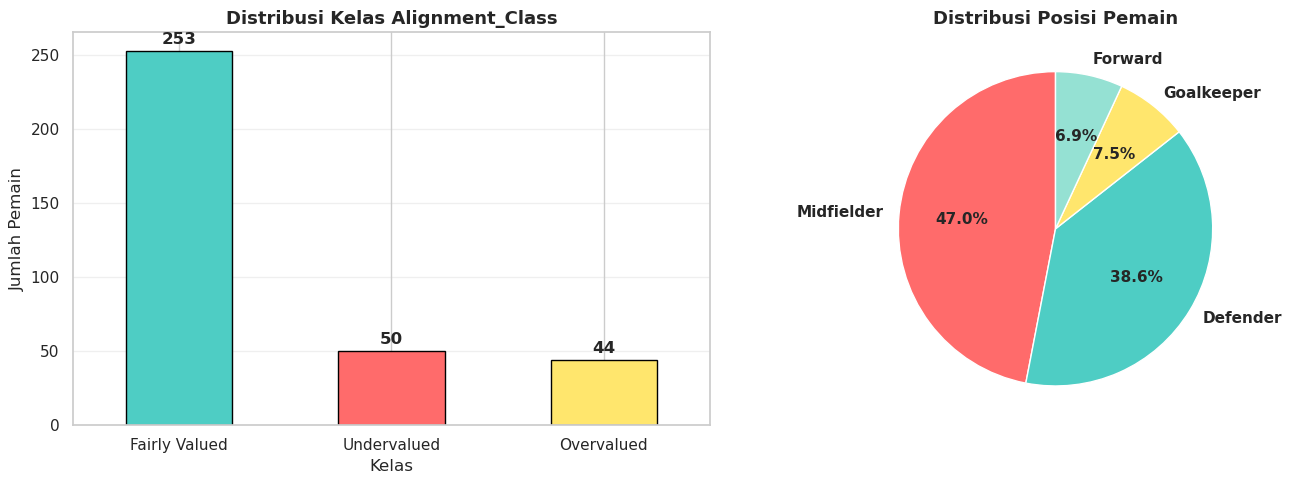


✓ Gambar disimpan: distribusi_kelas_posisi.png

TAHAP 3: ANALISIS KORELASI FITUR NUMERIK

Pasangan fitur dengan |r| > 0.8:
        Fitur_1               Fitur_2  Korelasi
0       Minutes               Starter  0.987468
2  Dispossessed  Unsuccessful_touches  0.849211
1    Clearances                Blocks  0.814066


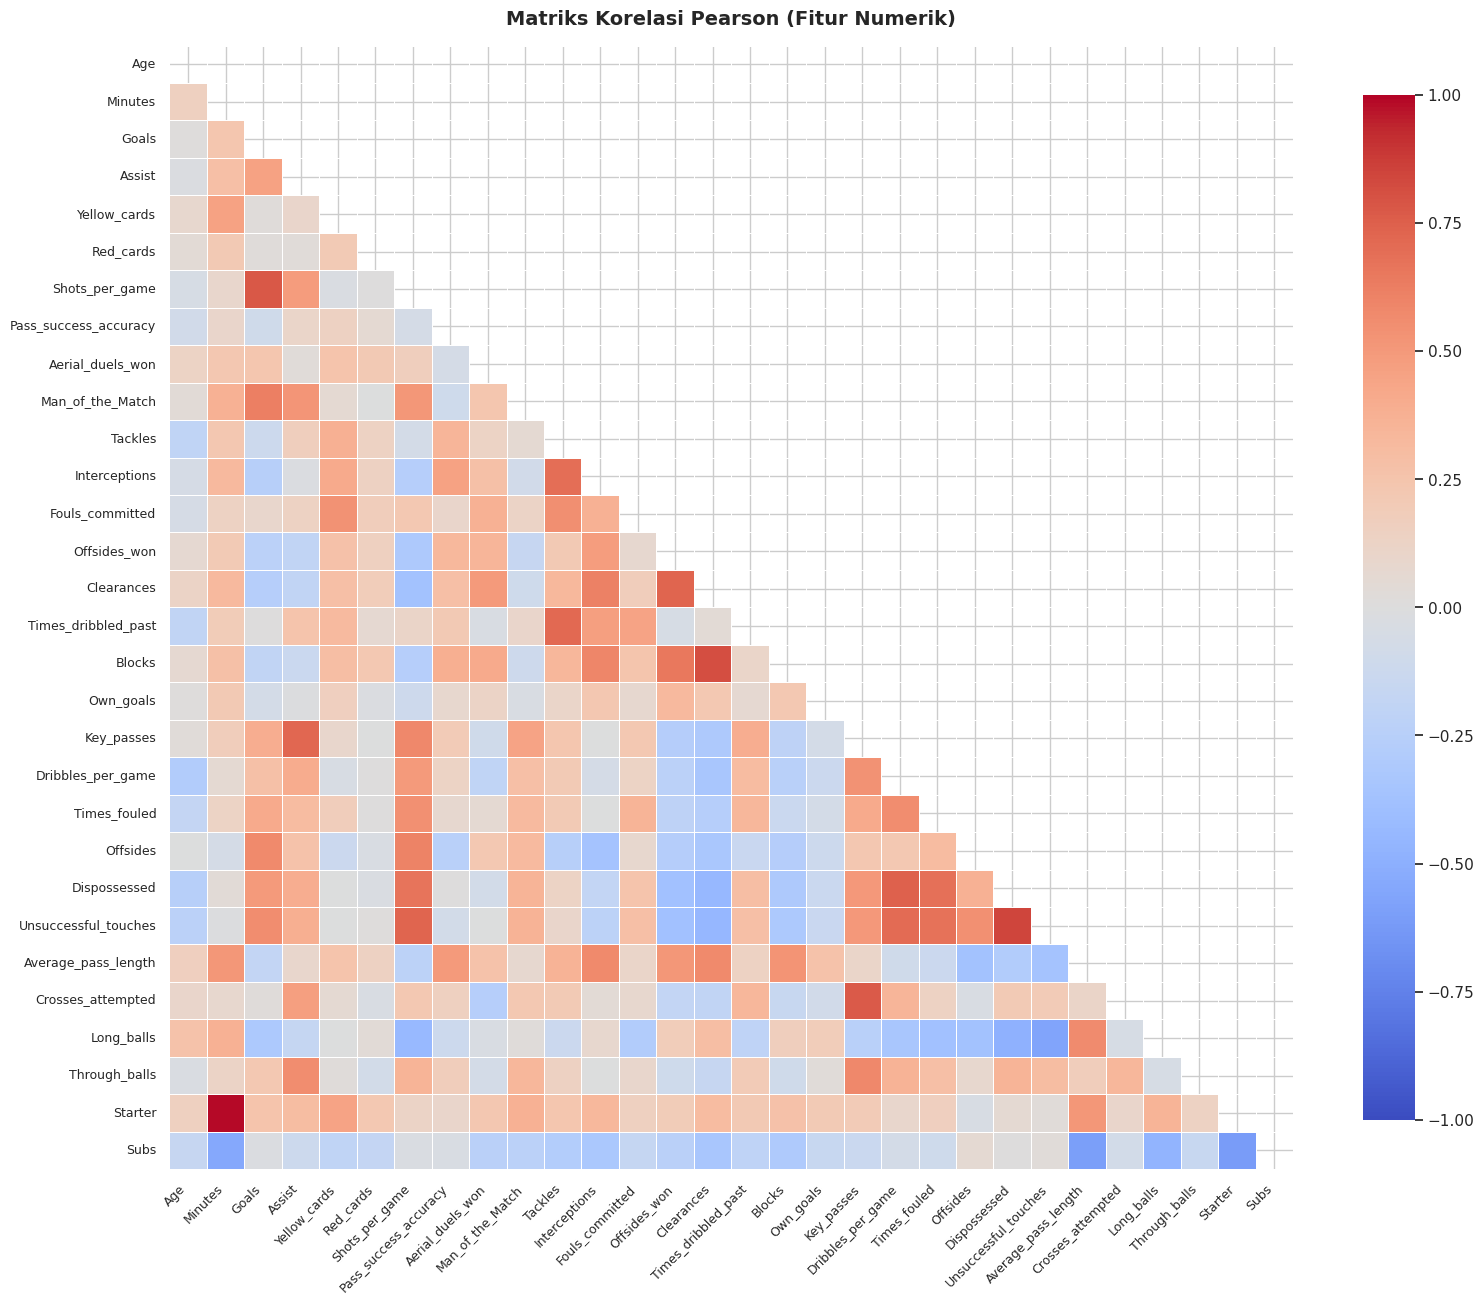


✓ Heatmap disimpan: correlation_heatmap_numerical.png

Top 10 fitur berkorelasi dengan target:
Long_balls             0.394196
Average_pass_length    0.188096
Minutes                0.183036
Starter                0.174994
Man_of_the_Match       0.169304
Age                    0.125132
Assist                 0.119040
Through_balls          0.081741
Goals                  0.060544
Key_passes             0.057823
dtype: float64

Bottom 10 fitur berkorelasi dengan target:
Unsuccessful_touches   -0.101699
Times_dribbled_past    -0.137669
Interceptions          -0.151142
Aerial_duels_won       -0.161367
Offsides_won           -0.168765
Blocks                 -0.187322
Clearances             -0.193571
Subs                   -0.198827
Tackles                -0.212958
Fouls_committed        -0.249294
dtype: float64

Catatan: Korelasi rendah (<0.3) wajar untuk klasifikasi multiclass (3 kelas).

TAHAP 4: PREPROCESSING & SPLIT DATA

Ukuran data train: 277 sampel
Ukuran data test: 70 sampel

TAHA

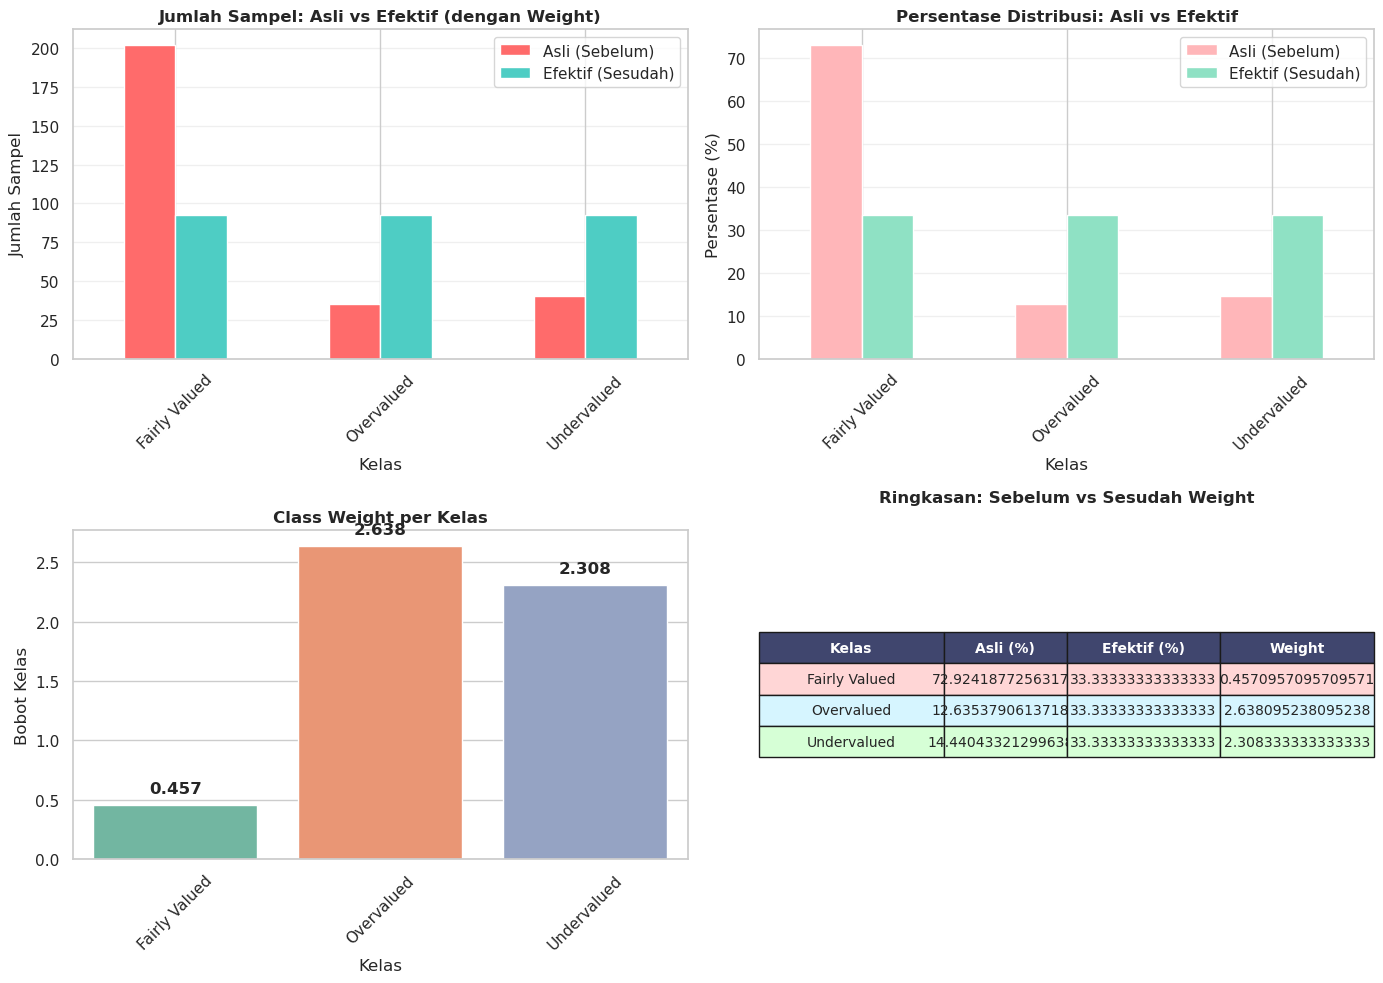


✓ Gambar disimpan: comparison_class_weight_sample_weight.png

TAHAP 6: OPTIMISASI RANDOM FOREST (GridSearchCV)
Fitting 5 folds for each of 432 candidates, totalling 2160 fits

✓ Selesai RF GridSearch dalam 111.20 detik
RF params terbaik: {'classifier__class_weight': {'Fairly Valued': 0.4570957095709571, 'Overvalued': 2.638095238095238, 'Undervalued': 2.308333333333333}, 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 50}
RF CV F1-macro terbaik: 0.6692

--- Classification Report RF (Test Set) ---
               precision    recall  f1-score   support

Fairly Valued       0.88      0.86      0.87        51
   Overvalued       0.71      0.56      0.62         9
  Undervalued       0.62      0.80      0.70        10

     accuracy                           0.81        70
    macro avg       0.74      0.74      0.73        70
 weighted avg       0.82      0.81      0.81        70



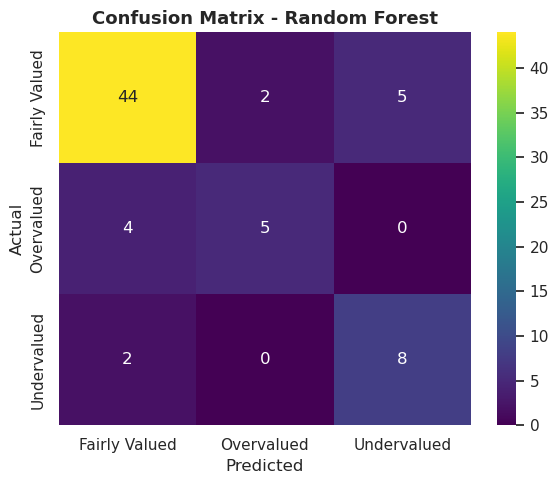


✓ Gambar disimpan: confusion_matrix_rf.png

--- Top 15 Feature Importance RF ---
                  feature  importance
24    Average_pass_length    0.084417
7   Pass_success_accuracy    0.084269
26             Long_balls    0.066803
12        Fouls_committed    0.058272
10                Tackles    0.052663
8        Aerial_duels_won    0.047588
23   Unsuccessful_touches    0.042116
6          Shots_per_game    0.041844
3                  Assist    0.039103
18             Key_passes    0.037407
33    Position_Midfielder    0.036866
1                 Minutes    0.034363
14             Clearances    0.033840
0                     Age    0.029469
15    Times_dribbled_past    0.029062


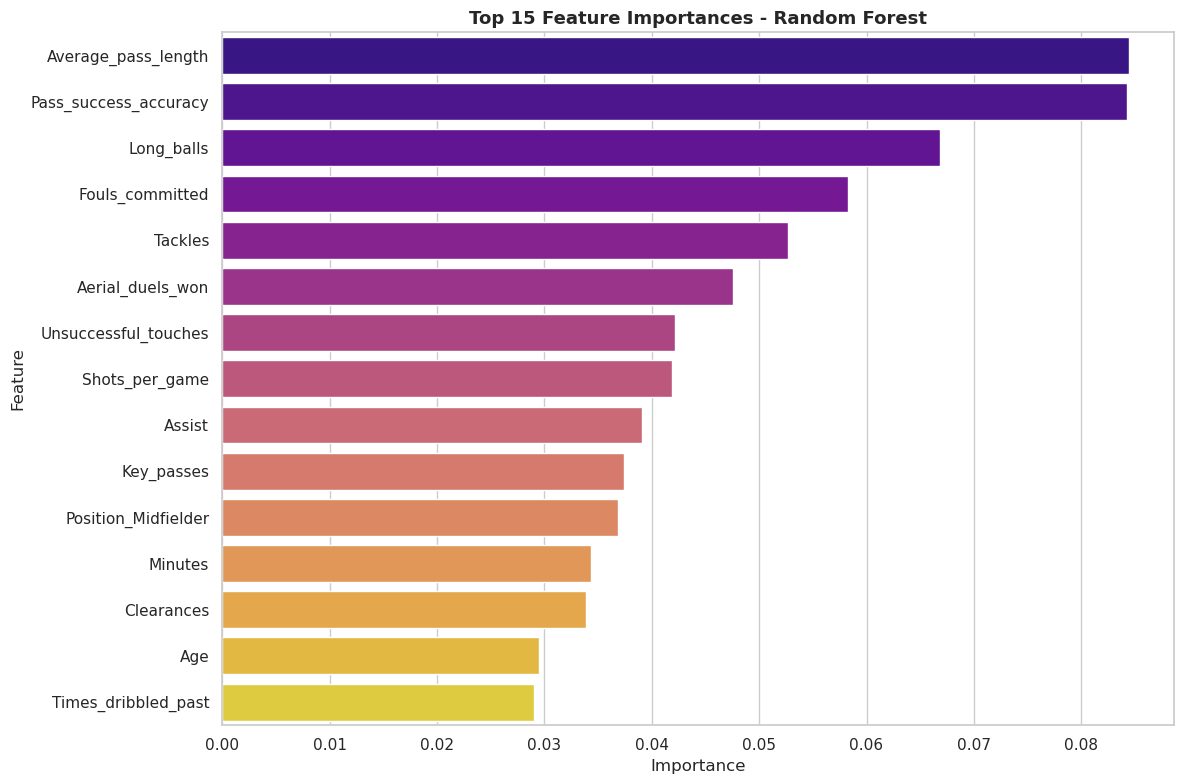


✓ Gambar disimpan: feature_importance_rf.png


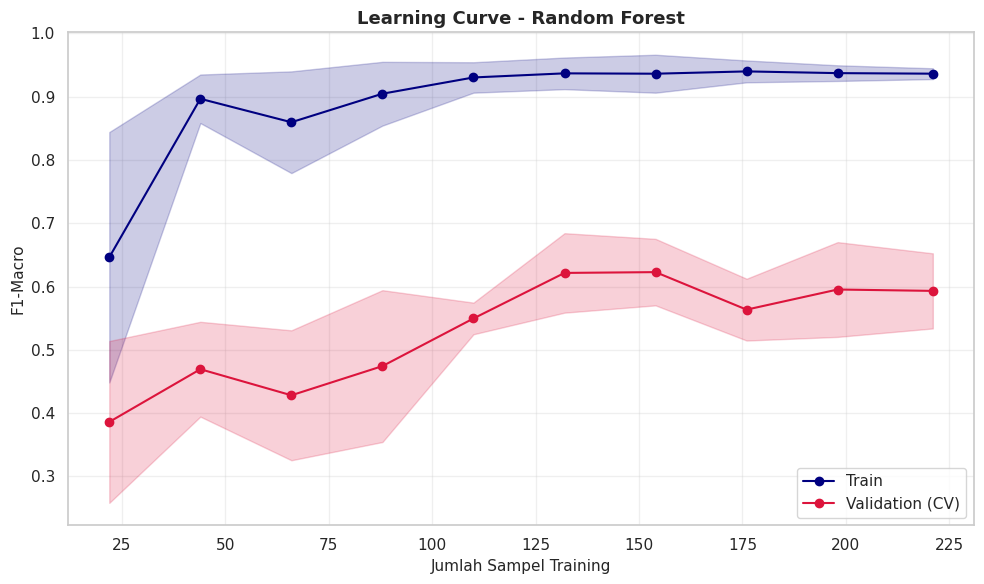


✓ Gambar disimpan: learning_curve_rf.png


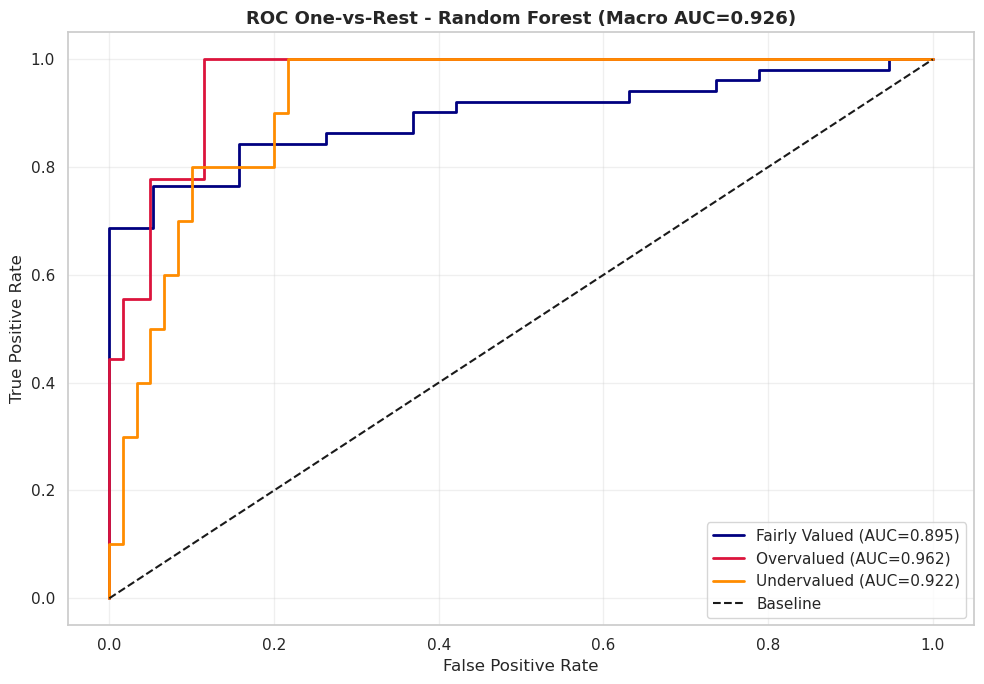


✓ Gambar disimpan: roc_curve_rf.png

TAHAP 7: OPTIMISASI GRADIENT BOOSTING (GridSearchCV)
Fitting 5 folds for each of 324 candidates, totalling 1620 fits

✓ Selesai GB GridSearch dalam 168.28 detik
GB params terbaik: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 50, 'classifier__subsample': 0.6}
GB CV F1-macro terbaik: 0.6605

--- Classification Report GB (Test Set) ---
               precision    recall  f1-score   support

Fairly Valued       0.90      0.84      0.87        51
   Overvalued       0.86      0.67      0.75         9
  Undervalued       0.47      0.70      0.56        10

     accuracy                           0.80        70
    macro avg       0.74      0.74      0.73        70
 weighted avg       0.83      0.80      0.81        70



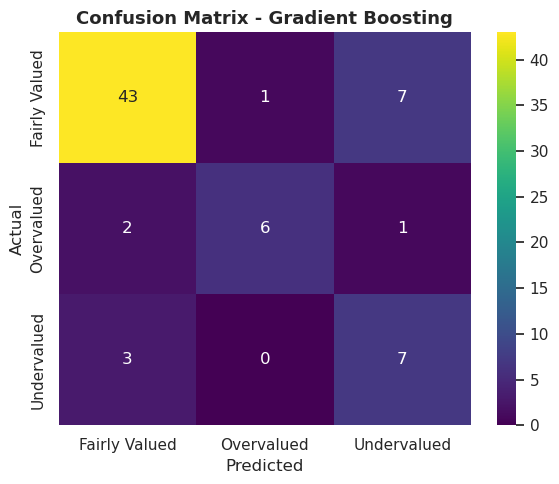


✓ Gambar disimpan: confusion_matrix_gb.png

--- Top 15 Feature Importance GB ---
                  feature  importance
24    Average_pass_length    0.142032
12        Fouls_committed    0.080785
7   Pass_success_accuracy    0.072292
8        Aerial_duels_won    0.068128
14             Clearances    0.063448
1                 Minutes    0.056576
0                     Age    0.049039
3                  Assist    0.047769
30      Position_Defender    0.036400
29                   Subs    0.035349
6          Shots_per_game    0.034978
10                Tackles    0.031189
26             Long_balls    0.030744
33    Position_Midfielder    0.024507
19      Dribbles_per_game    0.020716


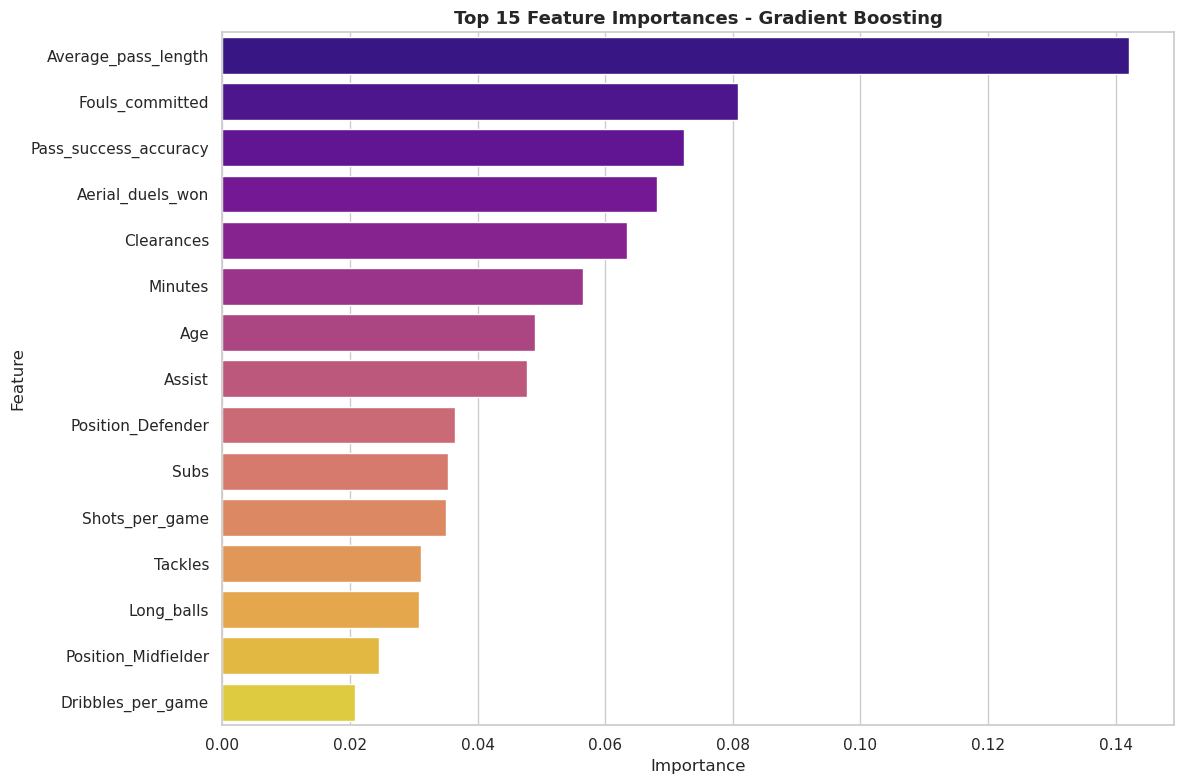


✓ Gambar disimpan: feature_importance_gb.png


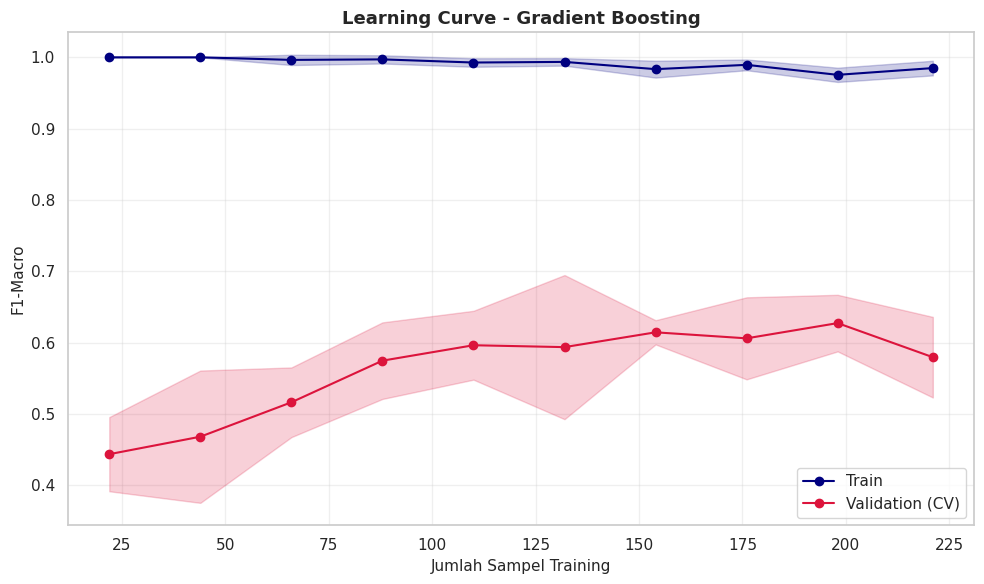


✓ Gambar disimpan: learning_curve_gb.png


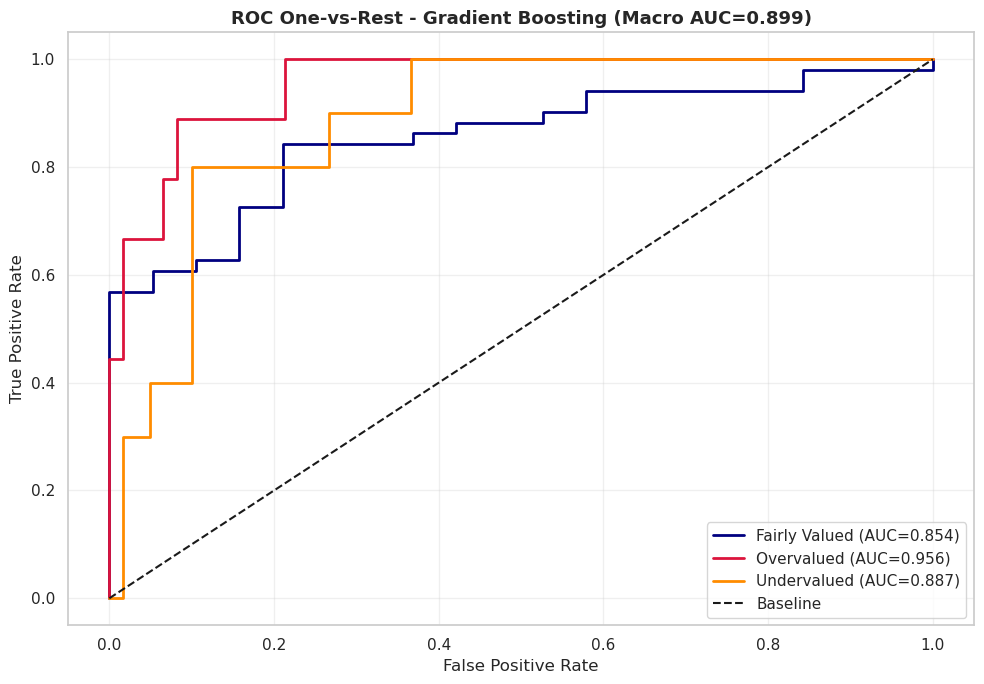


✓ Gambar disimpan: roc_curve_gb.png

TAHAP 8: PEMILIHAN MODEL TERBAIK & RINGKASAN KOMPARATIF

✓ MODEL TERBAIK: Random Forest
F1-macro (Test): 0.7306

--- RINGKASAN KOMPARATIF RF vs GB ---
  model  f1_macro_test  auc_macro_test  delta_f1_vs_RF
0    RF       0.730646        0.926051        0.000000
1    GB       0.726229        0.899147       -0.004417

--- NARASI KOMPARATIF (siap salin ke naskah) ---
Pada data uji, Random Forest meraih F1-makro 0.731 dengan AUC-makro 0.926.
Gradient Boosting meraih F1-makro 0.726 dan AUC-makro 0.899, lebih rendah sebesar 0.004 poin dibanding Random Forest.
Perbedaan ini konsisten dengan hasil validasi silang dan kurva ROC satu-lawan-semua, menunjukkan perbaikan separabilitas pada kelas minoritas tanpa resampling sintetis.

TAHAP 9: UJI SENSITIVITAS BOBOT SKOR PERFORMA

--- HASIL UJI SENSITIVITAS BOBOT SKOR PERFORMA ---
            scenario  f1_macro_mean  f1_macro_std
0               BASE       0.575969      0.044483
1       +10% Forward       0.575969

In [1]:
# ==============================================================================
# SKRIP ANALISIS TUGAS AKHIR: KLASIFIKASI KESELARASAN MARKET VALUE & PERFORMA
# Random Forest vs Gradient Boosting (Lengkap: Eksplorasi + Pemodelan + Evaluasi)
# Liga Eredivisie Belanda Musim 2023/2024
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
import json
import joblib
import copy
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, GridSearchCV, learning_curve,
    StratifiedKFold, cross_val_score
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    roc_auc_score, roc_curve, auc
)
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

# Konfigurasi visualisasi
pd.set_option('display.max_columns', None)
sns.set(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

print("="*80)
print("SKRIP ANALISIS KLASIFIKASI MARKET VALUE & PERFORMA PEMAIN EREDIVISIE 2023/2024")
print("="*80)

# ==============================================================================
# TAHAP 1: MUAT DATA + FEATURE ENGINEERING
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 1: MUAT DATA & FEATURE ENGINEERING")
print("="*80)

df = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))
print(f"\nDataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Kolom: {list(df.columns)}")

# Definisi bobot posisi-spesifik untuk Performance_Score
weights = {
    'Forward': {
        'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
        'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05
    },
    'Midfielder': {
        'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
        'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
        'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05
    },
    'Defender': {
        'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
        'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
        'Blocks': 0.05, 'Man_of_the_Match': 0.05
    },
    'Goalkeeper': {
        'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
        'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
        'Man_of_the_Match': 0.10
    }
}

def calculate_performance_score(row):
    pos = row['Position']
    score = 0.0
    if pos in weights:
        for feature, weight in weights[pos].items():
            score += row.get(feature, 0.0) * weight
    return score

# Hitung Performance_Score
df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                               (df['Performance_Score'].max() - df['Performance_Score'].min())
df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                      (df['Market_Value'].max() - df['Market_Value'].min())

# Buat kuartil (tangani ties)
df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                               labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                             labels=['Q1','Q2','Q3','Q4'], duplicates='drop')

# Klasifikasi Alignment_Class
def classify_alignment(row):
    perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
    if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
        return 'Undervalued'
    elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
        return 'Overvalued'
    else:
        return 'Fairly Valued'

df['Alignment_Class'] = df.apply(classify_alignment, axis=1)
print("\n✓ Feature engineering selesai (Performance_Score, Alignment_Class)")

# Distribusi kelas
print("\nDistribusi Alignment_Class:")
print(df['Alignment_Class'].value_counts())
print("\nPersentase distribusi:")
print(df['Alignment_Class'].value_counts(normalize=True) * 100)

# ==============================================================================
# TAHAP 2: EKSPLORASI DATA - STATISTIK DESKRIPTIF
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 2: EKSPLORASI DATA - STATISTIK DESKRIPTIF")
print("="*80)

# Statistik deskriptif fitur numerik
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("\nStatistik deskriptif (mean, std, min, max) untuk fitur numerik:")
print(df[numeric_cols].describe().T[['mean', 'std', 'min', 'max']])

# Distribusi posisi
print("\nDistribusi posisi pemain:")
print(df['Position'].value_counts())
print("\nPersentase per posisi:")
print(df['Position'].value_counts(normalize=True) * 100)

# Visualisasi distribusi kelas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart distribusi Alignment_Class
ax1 = axes[0]
class_counts = df['Alignment_Class'].value_counts()
colors_bar = ['#4ECDC4', '#FF6B6B', '#FFE66D']
class_counts.plot(kind='bar', ax=ax1, color=colors_bar, edgecolor='black')
ax1.set_title('Distribusi Kelas Alignment_Class', fontsize=13, fontweight='bold')
ax1.set_xlabel('Kelas')
ax1.set_ylabel('Jumlah Pemain')
ax1.grid(axis='y', alpha=0.3)
for i, v in enumerate(class_counts):
    ax1.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=0)

# Pie chart distribusi Position
ax2 = axes[1]
position_counts = df['Position'].value_counts()
colors_pie = ['#FF6B6B', '#4ECDC4', '#FFE66D', '#95E1D3']
ax2.pie(position_counts, labels=position_counts.index, autopct='%1.1f%%',
        colors=colors_pie, startangle=90, textprops={'fontsize': 11, 'weight': 'bold'})
ax2.set_title('Distribusi Posisi Pemain', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('distribusi_kelas_posisi.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: distribusi_kelas_posisi.png")

# ==============================================================================
# TAHAP 3: ANALISIS KORELASI FITUR NUMERIK
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 3: ANALISIS KORELASI FITUR NUMERIK")
print("="*80)

# Definisikan fitur dan target
target = 'Alignment_Class'
features_to_drop = [
    'Player', 'Market_Value',
    'Performance_Score', 'Perf_Score_Normalized', 'MV_Normalized',
    'Perf_Quantile', 'MV_Quantile', 'Alignment_Class'
]
features = [c for c in df.columns if c not in features_to_drop]
categorical_features = ['Position']
numerical_features = [c for c in features if c not in categorical_features]

# Hitung matriks korelasi
X_for_corr = df[numerical_features]
corr_matrix = X_for_corr.corr(method='pearson')

# Identifikasi korelasi tinggi (|r| > 0.8)
threshold = 0.8
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            high_corr.append({
                'Fitur_1': corr_matrix.columns[i],
                'Fitur_2': corr_matrix.columns[j],
                'Korelasi': corr_matrix.iloc[i, j]
            })

if high_corr:
    print(f"\nPasangan fitur dengan |r| > {threshold}:")
    high_corr_df = pd.DataFrame(high_corr).sort_values('Korelasi', ascending=False)
    print(high_corr_df)
else:
    print(f"\nTidak ada pasangan fitur dengan |r| > {threshold}.")
    print("Kesimpulan: Tidak ada multikolinearitas ekstrem.")

# Visualisasi heatmap korelasi
fig, ax = plt.subplots(figsize=(16, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm',
            center=0, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax, vmin=-1, vmax=1)
ax.set_title('Matriks Korelasi Pearson (Fitur Numerik)',
             fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('correlation_heatmap_numerical.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Heatmap disimpan: correlation_heatmap_numerical.png")

# Korelasi fitur dengan target (encode target ke numerik)
le_target = LabelEncoder()
y_encoded = le_target.fit_transform(df[target])
corr_with_target = X_for_corr.corrwith(pd.Series(y_encoded, index=X_for_corr.index), 
                                        method='pearson').sort_values(ascending=False)

print("\nTop 10 fitur berkorelasi dengan target:")
print(corr_with_target.head(10))
print("\nBottom 10 fitur berkorelasi dengan target:")
print(corr_with_target.tail(10))
print("\nCatatan: Korelasi rendah (<0.3) wajar untuk klasifikasi multiclass (3 kelas).")

# ==============================================================================
# TAHAP 4: PREPROCESSING & SPLIT DATA
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 4: PREPROCESSING & SPLIT DATA")
print("="*80)

X = df[features]
y = df[target]

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Split data 80:20 dengan stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# --- TAMBAHAN PENTING: SIMPAN INDEX ASLI ---
train_indices = X_train.index
test_indices = X_test.index
# -------------------------------------------

print(f"\nUkuran data train: {X_train.shape[0]} sampel")
print(f"Ukuran data test: {X_test.shape[0]} sampel")

# ==============================================================================
# TAHAP 5: CLASS_WEIGHT & SAMPLE_WEIGHT (SEBELUM-SESUDAH)
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 5: ANALISIS CLASS_WEIGHT & SAMPLE_WEIGHT")
print("="*80)

# SEBELUM: Distribusi kelas asli
print("\n--- SEBELUM: Distribusi Kelas Original (Tidak Seimbang) ---")
class_dist_before = y_train.value_counts(normalize=False)
class_pct_before = y_train.value_counts(normalize=True) * 100
print("\nJumlah sampel per kelas:")
print(class_dist_before)
print("\nPersentase distribusi kelas:")
print(class_pct_before)

# Hitung class_weight dan sample_weight
classes = np.unique(y_train)
cw_arr = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
cw_dict = dict(zip(classes, cw_arr))
sw_train = compute_sample_weight(class_weight=cw_dict, y=y_train)

print("\n--- CLASS_WEIGHT (Balanced) ---")
print("\nClass weight dictionary:")
for kelas, bobot in cw_dict.items():
    print(f"  {kelas}: {bobot:.4f}")

print("\n--- SAMPLE_WEIGHT (Berdasarkan Class Weight) ---")
print(f"\nJumlah sampel: {len(sw_train)}")
print(f"Min weight: {sw_train.min():.4f}")
print(f"Max weight: {sw_train.max():.4f}")
print(f"Mean weight: {sw_train.mean():.4f}")

# SESUDAH: Distribusi kelas efektif dengan bobot
weighted_dist = pd.DataFrame({'Kelas': y_train.values, 'Weight': sw_train})
effective_dist = weighted_dist.groupby('Kelas')['Weight'].sum()
effective_pct = (effective_dist / effective_dist.sum()) * 100

print("\n--- SESUDAH: Distribusi Kelas Efektif (Dengan Sample Weight) ---")
print("\nJumlah sampel efektif (setelah bobot):")
print(effective_dist)
print("\nPersentase efektif (setelah bobot):")
print(effective_pct)

# Tabel perbandingan
comparison_df = pd.DataFrame({
    'Kelas': classes,
    'Jumlah_Asli': [class_dist_before[c] for c in classes],
    'Persen_Asli': [class_pct_before[c] for c in classes],
    'Class_Weight': [cw_dict[c] for c in classes],
    'Jumlah_Efektif': [effective_dist[c] for c in classes],
    'Persen_Efektif': [effective_pct[c] for c in classes]
})

print("\n--- RINGKASAN PERBANDINGAN SEBELUM vs SESUDAH ---")
print(comparison_df.to_string(index=False))

# Visualisasi perbandingan distribusi sebelum-sesudah
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Jumlah sampel asli vs efektif
ax1 = axes[0, 0]
comparison_df[['Kelas', 'Jumlah_Asli', 'Jumlah_Efektif']].set_index('Kelas').plot(
    kind='bar', ax=ax1, color=['#FF6B6B', '#4ECDC4']
)
ax1.set_title('Jumlah Sampel: Asli vs Efektif (dengan Weight)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Jumlah Sampel')
ax1.set_xlabel('Kelas')
ax1.legend(['Asli (Sebelum)', 'Efektif (Sesudah)'])
ax1.grid(axis='y', alpha=0.3)
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45)

# Plot 2: Persentase asli vs efektif
ax2 = axes[0, 1]
comparison_df[['Kelas', 'Persen_Asli', 'Persen_Efektif']].set_index('Kelas').plot(
    kind='bar', ax=ax2, color=['#FFB6B9', '#8FE1C4']
)
ax2.set_title('Persentase Distribusi: Asli vs Efektif', fontsize=12, fontweight='bold')
ax2.set_ylabel('Persentase (%)')
ax2.set_xlabel('Kelas')
ax2.legend(['Asli (Sebelum)', 'Efektif (Sesudah)'])
ax2.grid(axis='y', alpha=0.3)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

# Plot 3: Class Weight per Kelas
ax3 = axes[1, 0]
sns.barplot(x=comparison_df['Kelas'], y=comparison_df['Class_Weight'],
            ax=ax3, palette='Set2')
ax3.set_title('Class Weight per Kelas', fontsize=12, fontweight='bold')
ax3.set_ylabel('Bobot Kelas')
ax3.set_xlabel('Kelas')
for i, v in enumerate(comparison_df['Class_Weight']):
    ax3.text(i, v + 0.1, f'{v:.3f}', ha='center', fontweight='bold')
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45)

# Plot 4: Tabel ringkasan
ax4 = axes[1, 1]
ax4.axis('off')
table_data = comparison_df[['Kelas', 'Persen_Asli', 'Persen_Efektif', 'Class_Weight']].values.tolist()
table_data.insert(0, ['Kelas', 'Asli (%)', 'Efektif (%)', 'Weight'])
table = ax4.table(cellText=table_data, loc='center', cellLoc='center',
                  colWidths=[0.3, 0.2, 0.25, 0.25])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
for i in range(4):
    table[(0, i)].set_facecolor('#40466e')
    table[(0, i)].set_text_props(weight='bold', color='white')
colors_table = ['#FFD6D6', '#D6F5FF', '#D6FFD6']
for i in range(1, 4):
    for j in range(4):
        table[(i, j)].set_facecolor(colors_table[i-1])
ax4.set_title('Ringkasan: Sebelum vs Sesudah Weight',
              fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('comparison_class_weight_sample_weight.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: comparison_class_weight_sample_weight.png")

# ==============================================================================
# TAHAP 6: OPTIMISASI RANDOM FOREST
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 6: OPTIMISASI RANDOM FOREST (GridSearchCV)")
print("="*80)

rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'classifier__n_estimators': [50, 100, 150, 200],
    'classifier__max_depth': [5, 10, 15, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 3, 5],
    'classifier__class_weight': [cw_dict, 'balanced', None]
}

gs_rf = GridSearchCV(rf_pipe, param_grid=param_grid_rf,
                     cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)

t0 = time.time()
gs_rf.fit(X_train, y_train)
t1 = time.time()

print(f"\n✓ Selesai RF GridSearch dalam {t1-t0:.2f} detik")
print(f"RF params terbaik: {gs_rf.best_params_}")
print(f"RF CV F1-macro terbaik: {gs_rf.best_score_:.4f}")

# Evaluasi pada test set
y_pred_rf = gs_rf.best_estimator_.predict(X_test)
print("\n--- Classification Report RF (Test Set) ---")
print(classification_report(y_test, y_pred_rf))

# Confusion Matrix RF
rf_clf = gs_rf.best_estimator_.named_steps['classifier']
labels_rf = list(rf_clf.classes_)
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels_rf)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='viridis',
            xticklabels=labels_rf, yticklabels=labels_rf)
plt.title('Confusion Matrix - Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: confusion_matrix_rf.png")

# Feature Importance RF
cat_names = list(gs_rf.best_estimator_.named_steps['preprocessor'].\
                named_transformers_['cat'].get_feature_names_out(categorical_features))
feat_names = numerical_features + cat_names
imp_rf = rf_clf.feature_importances_
fi_rf = pd.DataFrame({'feature': feat_names, 'importance': imp_rf}).\
        sort_values('importance', ascending=False)

print("\n--- Top 15 Feature Importance RF ---")
print(fi_rf.head(15))

plt.figure(figsize=(12,8))
sns.barplot(x='importance', y='feature', data=fi_rf.head(15), palette='plasma')
plt.title('Top 15 Feature Importances - Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('feature_importance_rf.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: feature_importance_rf.png")

# Learning Curve RF
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sizes = np.linspace(0.1, 1.0, 10)
sizes_abs, tr_rf, va_rf = learning_curve(
    gs_rf.best_estimator_, X_train, y_train,
    train_sizes=sizes, cv=cv5, scoring='f1_macro', shuffle=True, n_jobs=-1
)

plt.figure(figsize=(10,6))
plt.plot(sizes_abs, tr_rf.mean(axis=1), 'o-', label='Train', color='navy')
plt.fill_between(sizes_abs, tr_rf.mean(axis=1)-tr_rf.std(axis=1),
                 tr_rf.mean(axis=1)+tr_rf.std(axis=1), alpha=0.2, color='navy')
plt.plot(sizes_abs, va_rf.mean(axis=1), 'o-', label='Validation (CV)', color='crimson')
plt.fill_between(sizes_abs, va_rf.mean(axis=1)-va_rf.std(axis=1),
                 va_rf.mean(axis=1)+va_rf.std(axis=1), alpha=0.2, color='crimson')
plt.xlabel('Jumlah Sampel Training', fontsize=11)
plt.ylabel('F1-Macro', fontsize=11)
plt.title('Learning Curve - Random Forest', fontsize=13, fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('learning_curve_rf.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: learning_curve_rf.png")

# ROC-AUC Multi-kelas RF
proba_rf = gs_rf.best_estimator_.predict_proba(X_test)
rf_classes = rf_clf.classes_
y_test_bin = label_binarize(y_test, classes=rf_classes)

fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(rf_classes)):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], proba_rf[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

macro_auc_rf = roc_auc_score(y_test_bin, proba_rf, average='macro', multi_class='ovr')

plt.figure(figsize=(10,7))
colors = ['navy','crimson','darkorange','seagreen','purple']
for i, c in enumerate(rf_classes):
    plt.plot(fpr[i], tpr[i], lw=2, color=colors[i%len(colors)],
             label=f'{c} (AUC={roc_auc[i]:.3f})')
plt.plot([0,1],[0,1],'k--', label='Baseline')
plt.title(f'ROC One-vs-Rest - Random Forest (Macro AUC={macro_auc_rf:.3f})',
          fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(loc='lower right'); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_rf.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: roc_curve_rf.png")

# ==============================================================================
# TAHAP 7: OPTIMISASI GRADIENT BOOSTING
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 7: OPTIMISASI GRADIENT BOOSTING (GridSearchCV)")
print("="*80)

gb_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

param_grid_gb = {
    'classifier__n_estimators': [50, 100, 150, 200],
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__max_depth': [3, 4, 5],
    'classifier__subsample': [0.6, 0.7, 0.8],
    'classifier__min_samples_leaf': [2, 5, 10]
}

gs_gb = GridSearchCV(gb_pipe, param_grid=param_grid_gb,
                     cv=5, scoring='f1_macro', verbose=1, n_jobs=-1)

t0 = time.time()
gs_gb.fit(X_train, y_train, **{'classifier__sample_weight': sw_train})
t1 = time.time()

print(f"\n✓ Selesai GB GridSearch dalam {t1-t0:.2f} detik")
print(f"GB params terbaik: {gs_gb.best_params_}")
print(f"GB CV F1-macro terbaik: {gs_gb.best_score_:.4f}")

# Evaluasi pada test set
y_pred_gb = gs_gb.best_estimator_.predict(X_test)
print("\n--- Classification Report GB (Test Set) ---")
print(classification_report(y_test, y_pred_gb))

# Confusion Matrix GB
gb_clf = gs_gb.best_estimator_.named_steps['classifier']
labels_gb = list(gb_clf.classes_)
cm_gb = confusion_matrix(y_test, y_pred_gb, labels=labels_gb)

plt.figure(figsize=(6,5))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='viridis',
            xticklabels=labels_gb, yticklabels=labels_gb)
plt.title('Confusion Matrix - Gradient Boosting', fontsize=13, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('confusion_matrix_gb.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: confusion_matrix_gb.png")

# Feature Importance GB
imp_gb = gb_clf.feature_importances_
fi_gb = pd.DataFrame({'feature': feat_names, 'importance': imp_gb}).\
        sort_values('importance', ascending=False)

print("\n--- Top 15 Feature Importance GB ---")
print(fi_gb.head(15))

plt.figure(figsize=(12,8))
sns.barplot(x='importance', y='feature', data=fi_gb.head(15), palette='plasma')
plt.title('Top 15 Feature Importances - Gradient Boosting', fontsize=13, fontweight='bold')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('feature_importance_gb.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: feature_importance_gb.png")

# Learning Curve GB
sizes_abs, tr_gb, va_gb = learning_curve(
    gs_gb.best_estimator_, X_train, y_train,
    train_sizes=sizes, cv=cv5, scoring='f1_macro', shuffle=True, n_jobs=-1,
    fit_params={'classifier__sample_weight': sw_train}
)

plt.figure(figsize=(10,6))
plt.plot(sizes_abs, tr_gb.mean(axis=1), 'o-', label='Train', color='navy')
plt.fill_between(sizes_abs, tr_gb.mean(axis=1)-tr_gb.std(axis=1),
                 tr_gb.mean(axis=1)+tr_gb.std(axis=1), alpha=0.2, color='navy')
plt.plot(sizes_abs, va_gb.mean(axis=1), 'o-', label='Validation (CV)', color='crimson')
plt.fill_between(sizes_abs, va_gb.mean(axis=1)-va_gb.std(axis=1),
                 va_gb.mean(axis=1)+va_gb.std(axis=1), alpha=0.2, color='crimson')
plt.xlabel('Jumlah Sampel Training', fontsize=11)
plt.ylabel('F1-Macro', fontsize=11)
plt.title('Learning Curve - Gradient Boosting', fontsize=13, fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('learning_curve_gb.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: learning_curve_gb.png")

# ROC-AUC Multi-kelas GB
proba_gb = gs_gb.best_estimator_.predict_proba(X_test)
gb_classes = gb_clf.classes_
y_test_bin_gb = label_binarize(y_test, classes=gb_classes)

fpr_gb, tpr_gb, roc_auc_gb = {}, {}, {}
for i in range(len(gb_classes)):
    fpr_gb[i], tpr_gb[i], _ = roc_curve(y_test_bin_gb[:, i], proba_gb[:, i])
    roc_auc_gb[i] = auc(fpr_gb[i], tpr_gb[i])

macro_auc_gb = roc_auc_score(y_test_bin_gb, proba_gb, average='macro', multi_class='ovr')

plt.figure(figsize=(10,7))
for i, c in enumerate(gb_classes):
    plt.plot(fpr_gb[i], tpr_gb[i], lw=2, color=colors[i%len(colors)],
             label=f'{c} (AUC={roc_auc_gb[i]:.3f})')
plt.plot([0,1],[0,1],'k--', label='Baseline')
plt.title(f'ROC One-vs-Rest - Gradient Boosting (Macro AUC={macro_auc_gb:.3f})',
          fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(loc='lower right'); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_gb.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: roc_curve_gb.png")

# ==============================================================================
# TAHAP 8: PEMILIHAN MODEL TERBAIK & RINGKASAN KOMPARATIF
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 8: PEMILIHAN MODEL TERBAIK & RINGKASAN KOMPARATIF")
print("="*80)

f1_rf = f1_score(y_test, y_pred_rf, average='macro')
f1_gb = f1_score(y_test, y_pred_gb, average='macro')

if f1_gb >= f1_rf:
    best_name = 'Gradient Boosting'
    best_est = gs_gb.best_estimator_
    best_f1 = f1_gb
else:
    best_name = 'Random Forest'
    best_est = gs_rf.best_estimator_
    best_f1 = f1_rf

print(f"\n✓ MODEL TERBAIK: {best_name}")
print(f"F1-macro (Test): {best_f1:.4f}")

# Tabel ringkasan komparatif
summary_cmp = pd.DataFrame([
    {'model': 'RF', 'f1_macro_test': f1_rf, 'auc_macro_test': macro_auc_rf},
    {'model': 'GB', 'f1_macro_test': f1_gb, 'auc_macro_test': macro_auc_gb},
]).sort_values('f1_macro_test', ascending=False).reset_index(drop=True)

rf_f1 = summary_cmp.loc[summary_cmp['model']=='RF','f1_macro_test'].values[0]
summary_cmp['delta_f1_vs_RF'] = summary_cmp['f1_macro_test'] - rf_f1

print("\n--- RINGKASAN KOMPARATIF RF vs GB ---")
print(summary_cmp)

# Narasi otomatis
def narrative_comparison(df_summary):
    if set(df_summary['model']) >= {'RF','GB'}:
        rf = df_summary[df_summary['model']=='RF'].iloc[0]
        gb = df_summary[df_summary['model']=='GB'].iloc[0]
        better = "lebih tinggi" if gb['f1_macro_test'] > rf['f1_macro_test'] else "lebih rendah"
        diff = abs(gb['f1_macro_test'] - rf['f1_macro_test'])
        lines = []
        lines.append(f"Pada data uji, Random Forest meraih F1-makro {rf['f1_macro_test']:.3f} dengan AUC-makro {rf['auc_macro_test']:.3f}.")
        lines.append(f"Gradient Boosting meraih F1-makro {gb['f1_macro_test']:.3f} dan AUC-makro {gb['auc_macro_test']:.3f}, {better} sebesar {diff:.3f} poin dibanding Random Forest.")
        lines.append("Perbedaan ini konsisten dengan hasil validasi silang dan kurva ROC satu-lawan-semua, menunjukkan perbaikan separabilitas pada kelas minoritas tanpa resampling sintetis.")
        return "\n".join(lines)
    else:
        return "Ringkasan komparatif tidak lengkap."

print("\n--- NARASI KOMPARATIF (siap salin ke naskah) ---")
print(narrative_comparison(summary_cmp))

# ==============================================================================
# TAHAP 9: UJI SENSITIVITAS BOBOT SKOR PERFORMA
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 9: UJI SENSITIVITAS BOBOT SKOR PERFORMA")
print("="*80)

def renorm(d):
    s = sum(d.values())
    return {k: (v / s if s > 0 else 0.0) for k, v in d.items()}

def apply_weight_modifier(base_weights, modifier):
    W = copy.deepcopy(base_weights)
    for pos, scale in modifier.get('pos_scale', {}).items():
        if pos in W:
            for feat in W[pos]:
                W[pos][feat] *= scale
            W[pos] = renorm(W[pos])
    for pos, tweaks in modifier.get('feat_add', {}).items():
        if pos in W:
            for feat, delta in tweaks.items():
                if feat in W[pos]:
                    W[pos][feat] = max(0.0, W[pos][feat] + delta)
            W[pos] = renorm(W[pos])
    return W

def compute_perf_score_with(weights_map, df_in):
    def calc(row):
        pos = row['Position']
        if pos not in weights_map:
            return 0.0
        return sum(row.get(feat, 0.0) * w for feat, w in weights_map[pos].items())
    return df_in.apply(calc, axis=1)

def derive_labels_from_perf_and_mv(df_in, perf_col='Performance_Score'):
    tmp = df_in.copy()
    tmp['Perf_Score_Normalized'] = (tmp[perf_col] - tmp[perf_col].min()) / (tmp[perf_col].max() - tmp[perf_col].min())
    tmp['MV_Normalized'] = (tmp['Market_Value'] - tmp['Market_Value'].min()) / (tmp['Market_Value'].max() - tmp['Market_Value'].min())
    tmp['Perf_Quantile'] = pd.qcut(tmp['Perf_Score_Normalized'], 4, labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    tmp['MV_Quantile']   = pd.qcut(tmp['MV_Normalized'], 4, labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    def classify_alignment_fast(row):
        if row['Perf_Quantile'] == 'Q4' and row['MV_Quantile'] != 'Q4':
            return 'Undervalued'
        elif row['MV_Quantile'] == 'Q4' and row['Perf_Quantile'] != 'Q4':
            return 'Overvalued'
        else:
            return 'Fairly Valued'
    return tmp.apply(classify_alignment_fast, axis=1)

def run_sensitivity(df_base, base_weights, scenarios, features, categorical_features, model='GB'):
    results = []
    for name, modifier in scenarios.items():
        W = apply_weight_modifier(base_weights, modifier)
        df_tmp = df_base.copy()
        df_tmp['Performance_Score'] = compute_perf_score_with(W, df_tmp)
        y_tmp = derive_labels_from_perf_and_mv(df_tmp, perf_col='Performance_Score')
        X_tmp = df_tmp[features]
        if model == 'RF':
            base_model = RandomForestClassifier(random_state=42, n_jobs=-1)
        else:
            base_model = GradientBoostingClassifier(random_state=42)
        preproc = ColumnTransformer([
            ('num', 'passthrough', [c for c in features if c not in categorical_features]),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ])
        pipe = Pipeline([('preprocessor', preproc), ('clf', base_model)])
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        scores = cross_val_score(pipe, X_tmp, y_tmp, cv=skf, scoring='f1_macro', n_jobs=-1)
        results.append({
            'scenario': name,
            'f1_macro_mean': scores.mean(),
            'f1_macro_std': scores.std()
        })
    return pd.DataFrame(results)

sensitivity_scenarios = {
    'BASE': {},
    '+10% Forward': {'pos_scale': {'Forward': 1.10}},
    '-10% Forward': {'pos_scale': {'Forward': 0.90}},
    '+10% Midfielder': {'pos_scale': {'Midfielder': 1.10}},
    '+10% Defender': {'pos_scale': {'Defender': 1.10}},
    'FWD +0.05 Goals': {'feat_add': {'Forward': {'Goals': 0.05}}},
    'MID +0.05 Assist': {'feat_add': {'Midfielder': {'Assist': 0.05}}},
    'DEF +0.05 Tackles': {'feat_add': {'Defender': {'Tackles': 0.05}}},
}

sensitivity_df = run_sensitivity(
    df_base=df,
    base_weights=weights,
    scenarios=sensitivity_scenarios,
    features=features,
    categorical_features=categorical_features,
    model='GB'
)

print("\n--- HASIL UJI SENSITIVITAS BOBOT SKOR PERFORMA ---")
print(sensitivity_df)

# ==============================================================================
# TAHAP 10: SIMPAN ARTEFAK HASIL
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 10: SIMPAN ARTEFAK HASIL")
print("="*80)

joblib.dump(gs_rf.best_estimator_, os.path.join('../models' if os.path.exists('../models') else 'models', 'best_rf_model.pkl'))
joblib.dump(gs_gb.best_estimator_, os.path.join('../models' if os.path.exists('../models') else 'models', 'best_gb_model.pkl'))
print("\n✓ Model disimpan: best_rf_model.pkl, best_gb_model.pkl")

metrics_summary = {
    'rf': {
        'f1_macro_test': float(f1_rf),
        'auc_macro_test': float(macro_auc_rf),
        'best_params': gs_rf.best_params_,
        'cv_f1_macro': float(gs_rf.best_score_)
    },
    'gb': {
        'f1_macro_test': float(f1_gb),
        'auc_macro_test': float(macro_auc_gb),
        'best_params': gs_gb.best_params_,
        'cv_f1_macro': float(gs_gb.best_score_)
    }
}

with open('summary_metrics.json','w') as f:
    json.dump(metrics_summary, f, indent=2)
print("✓ Metrik disimpan: summary_metrics.json")

fi_rf.to_csv('feature_importance_rf.csv', index=False)
fi_gb.to_csv('feature_importance_gb.csv', index=False)
print("✓ Feature importance disimpan: feature_importance_rf.csv, feature_importance_gb.csv")

sensitivity_df.to_csv('sensitivity_analysis.csv', index=False)
print("✓ Uji sensitivitas disimpan: sensitivity_analysis.csv")

comparison_df.to_csv('comparison_class_weight.csv', index=False)
print("✓ Perbandingan class weight disimpan: comparison_class_weight.csv")

print("\n" + "="*80)
print("ANALISIS SELESAI - SEMUA ARTEFAK TELAH DISIMPAN")
print("="*80)
print(f"\n✓ MODEL TERBAIK: {best_name} (F1-macro: {best_f1:.4f})")
print("\n✓ File yang dihasilkan:")
print("  - 12 gambar visualisasi (.png)")
print("  - 2 model pickle (.pkl)")
print("  - 4 file CSV (FI, sensitivitas, class weight)")
print("  - 1 file JSON (metrik ringkasan)")



--- Hasil Perhitungan Class Weights ---
Class Weights (dictionary):
  Fairly Valued: 0.457
  Overvalued: 2.638
  Undervalued: 2.308

Sample weights untuk 277 sampel telah dihitung.
Range sample weights: 0.457 - 2.638

Tabel 5.6 Bobot Kelas yang Diterapkan pada Data Latih
     Kategori  Jumlah Sampel (Data Latih)  Bobot Kelas (Weight)
Fairly Valued                         202                 0.457
   Overvalued                          35                 2.638
  Undervalued                          40                 2.308

--- Analisis Rasio Bobot ---
Rasio bobot Undervalued terhadap Fairly Valued: 5.05x
Rasio bobot Overvalued terhadap Fairly Valued: 5.77x

Interpretasi: Kesalahan klasifikasi pada kelas minoritas mendapat penalti
sekitar 5.0x (Undervalued) dan 5.8x (Overvalued)
lebih besar dibandingkan kesalahan pada kelas mayoritas.

File tersimpan:
- Tabel_5_6_Bobot_Kelas.csv
- class_weights_dict.npy (untuk Random Forest)
- sample_weights_train.npy (untuk Gradient Boosting)


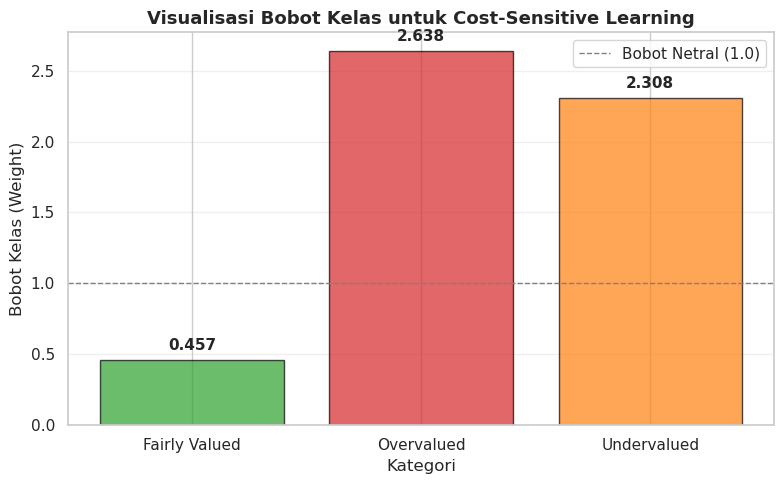


Visualisasi tersimpan: Gambar_5_8_Visualisasi_Bobot_Kelas.png


In [13]:
# ============================================================
# 5.4. Penanganan Ketidakseimbangan Kelas
# ============================================================

import pandas as pd
import numpy as np
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Perhitungan Class Weights (Cost-Sensitive Learning)
# ------------------------------------------------------------

# Hitung class weights menggunakan metode 'balanced'
classes = np.unique(y_train)
class_weights_array = compute_class_weight(
    class_weight='balanced', 
    classes=classes, 
    y=y_train
)

# Buat dictionary untuk class weights
class_weights_dict = dict(zip(classes, class_weights_array))

print("\n--- Hasil Perhitungan Class Weights ---")
print("Class Weights (dictionary):")
for cls, weight in class_weights_dict.items():
    print(f"  {cls}: {weight:.3f}")

# Hitung sample weights untuk Gradient Boosting
sample_weights_train = compute_sample_weight(
    class_weight=class_weights_dict, 
    y=y_train
)

print(f"\nSample weights untuk {len(sample_weights_train)} sampel telah dihitung.")
print(f"Range sample weights: {sample_weights_train.min():.3f} - {sample_weights_train.max():.3f}")

# ------------------------------------------------------------
# Buat Tabel 5.6: Bobot Kelas yang Diterapkan
# ------------------------------------------------------------

train_class_counts = y_train.value_counts()

tabel_5_6_data = []
for cls in ['Fairly Valued', 'Overvalued', 'Undervalued']:
    if cls in train_class_counts.index:
        tabel_5_6_data.append({
            'Kategori': cls,
            'Jumlah Sampel (Data Latih)': int(train_class_counts[cls]),
            'Bobot Kelas (Weight)': round(class_weights_dict[cls], 3)
        })

tabel_5_6 = pd.DataFrame(tabel_5_6_data)

print("\nTabel 5.6 Bobot Kelas yang Diterapkan pada Data Latih")
print(tabel_5_6.to_string(index=False))

tabel_5_6.to_csv("Tabel_5_6_Bobot_Kelas.csv", index=False)

# ------------------------------------------------------------
# Analisis Rasio Bobot
# ------------------------------------------------------------

print("\n--- Analisis Rasio Bobot ---")
bobot_mayoritas = class_weights_dict['Fairly Valued']
bobot_undervalued = class_weights_dict['Undervalued']
bobot_overvalued = class_weights_dict['Overvalued']

rasio_under = bobot_undervalued / bobot_mayoritas
rasio_over = bobot_overvalued / bobot_mayoritas

print(f"Rasio bobot Undervalued terhadap Fairly Valued: {rasio_under:.2f}x")
print(f"Rasio bobot Overvalued terhadap Fairly Valued: {rasio_over:.2f}x")
print("\nInterpretasi: Kesalahan klasifikasi pada kelas minoritas mendapat penalti")
print(f"sekitar {rasio_under:.1f}x (Undervalued) dan {rasio_over:.1f}x (Overvalued)")
print("lebih besar dibandingkan kesalahan pada kelas mayoritas.")

# ------------------------------------------------------------
# Simpan Hasil untuk Pemodelan
# ------------------------------------------------------------

np.save('class_weights_dict.npy', class_weights_dict)
np.save('sample_weights_train.npy', sample_weights_train)
print("\nFile tersimpan:")
print("- Tabel_5_6_Bobot_Kelas.csv")
print("- class_weights_dict.npy (untuk Random Forest)")
print("- sample_weights_train.npy (untuk Gradient Boosting)")

# ------------------------------------------------------------
# Visualisasi Bobot Kelas
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
categories = [row['Kategori'] for _, row in tabel_5_6.iterrows()]
weights = [row['Bobot Kelas (Weight)'] for _, row in tabel_5_6.iterrows()]
colors = ['#2ca02c', '#d62728', '#ff7f0e']

bars = plt.bar(categories, weights, color=colors, alpha=0.7, edgecolor='black')
plt.ylabel('Bobot Kelas (Weight)', fontsize=12)
plt.xlabel('Kategori', fontsize=12)
plt.title('Visualisasi Bobot Kelas untuk Cost-Sensitive Learning', fontsize=13, fontweight='bold')
plt.axhline(y=1.0, color='gray', linestyle='--', linewidth=1, label='Bobot Netral (1.0)')

for bar, weight in zip(bars, weights):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.05,
             f'{weight:.3f}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('Gambar_5_8_Visualisasi_Bobot_Kelas.png', dpi=200)
plt.show()

print("\nVisualisasi tersimpan: Gambar_5_8_Visualisasi_Bobot_Kelas.png")


Memuat model dan data untuk analisis komparatif...
✓ Model RF dan GB berhasil dimuat
✓ Data berhasil direkonstruksi dan prediksi dibuat

5.7.1. PERBANDINGAN KINERJA MODEL

Tabel 5.11 Perbandingan Kinerja Model Random Forest dan Gradient Boosting pada Data Uji
           Metrik  Random Forest  Gradient Boosting
          Akurasi         0.8143             0.8000
Precision (Macro)         0.7366             0.7399
   Recall (Macro)         0.7394             0.7366
 F1-Score (Macro)         0.7306             0.7262
  ROC-AUC (Macro)         0.9261             0.8991


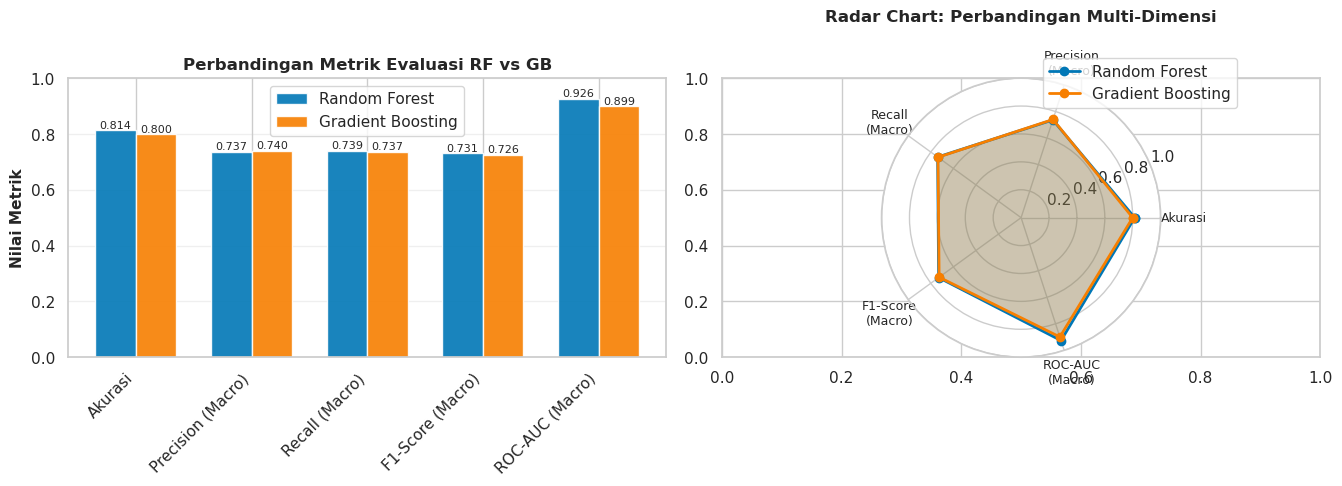


✓ Gambar disimpan: Gambar_5_11_Perbandingan_Model_RF_vs_GB.png

5.7.2. PEMILIHAN MODEL TERBAIK

🏆 MODEL TERPILIH: Random Forest
   F1-Macro: 0.7306
   ROC-AUC Macro: 0.9261

   Selisih F1-Macro dengan Gradient Boosting: 0.0044

--- ANALISIS BREAKDOWN PER KELAS ---

Perbandingan Per Kelas:
        Kelas  RF_Precision  GB_Precision  RF_Recall  GB_Recall  RF_F1  GB_F1
Fairly Valued          0.88          0.90       0.86       0.84   0.87   0.87
   Overvalued          0.71          0.86       0.56       0.67   0.62   0.75
  Undervalued          0.62          0.47       0.80       0.70   0.70   0.56

--- INSIGHT KEUNGGULAN ---
Gradient Boosting unggul pada:
  - Recall Overvalued: 0.67 vs 0.56

Random Forest unggul pada:
  - ROC-AUC Macro: 0.9261 vs 0.8991
  - Kemampuan diskriminasi probabilitas lebih baik

✓ File tersimpan:
- Tabel_5_11_Perbandingan_Kinerja_Model.csv
- Gambar_5_11_Perbandingan_Model_RF_vs_GB.png
- keputusan_model_terbaik.json

ANALISIS KOMPARATIF SELESAI

🎯 MODEL FINAL: Ra

In [14]:
# ============================================================
# 5.7. Analisis Komparatif dan Pemilihan Model Terbaik
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score, 
    precision_score, recall_score, roc_auc_score
)
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# ------------------------------------------------------------
# Load Model dan Data
# ------------------------------------------------------------
print("Memuat model dan data untuk analisis komparatif...")

try:
    # Load kedua model
    gs_rf_loaded = joblib.load('../models/best_rf_model.pkl' if os.path.exists('../models/best_rf_model.pkl') else ('models/best_rf_model.pkl' if os.path.exists('models/best_rf_model.pkl') else 'best_rf_model.pkl'))
    gs_gb_loaded = joblib.load('../models/best_gb_model.pkl' if os.path.exists('../models/best_gb_model.pkl') else ('models/best_gb_model.pkl' if os.path.exists('models/best_gb_model.pkl') else 'best_gb_model.pkl'))
    print("✓ Model RF dan GB berhasil dimuat")
    
    # Load data dan rekonstruksi
    df = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))
    
    weights = {
        'Forward': {'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
                    'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
        'Midfielder': {'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
                       'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
                       'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
        'Defender': {'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
                     'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
                     'Blocks': 0.05, 'Man_of_the_Match': 0.05},
        'Goalkeeper': {'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
                       'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
                       'Man_of_the_Match': 0.10}
    }
    
    def calculate_performance_score(row):
        pos = row['Position']
        score = 0.0
        if pos in weights:
            for feature, weight in weights[pos].items():
                score += row.get(feature, 0.0) * weight
        return score
    
    df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
    df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                                   (df['Performance_Score'].max() - df['Performance_Score'].min())
    df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                          (df['Market_Value'].max() - df['Market_Value'].min())
    df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                                   labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                                 labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    
    def classify_alignment(row):
        perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
        if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
            return 'Undervalued'
        elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
            return 'Overvalued'
        else:
            return 'Fairly Valued'
    
    df['Alignment_Class'] = df.apply(classify_alignment, axis=1)
    
    target = 'Alignment_Class'
    features_to_drop = ['Player', 'Market_Value', 'Performance_Score', 
                        'Perf_Score_Normalized', 'MV_Normalized',
                        'Perf_Quantile', 'MV_Quantile', 'Alignment_Class']
    features = [c for c in df.columns if c not in features_to_drop]
    
    X = df[features]
    y = df[target]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )
    
    # Prediksi dari kedua model
    y_pred_rf = gs_rf_loaded.predict(X_test)
    y_pred_gb = gs_gb_loaded.predict(X_test)
    
    # Prediksi probabilitas untuk ROC-AUC
    y_proba_rf = gs_rf_loaded.predict_proba(X_test)
    y_proba_gb = gs_gb_loaded.predict_proba(X_test)
    
    print("✓ Data berhasil direkonstruksi dan prediksi dibuat")
    
except FileNotFoundError as e:
    print(f"ERROR: {e}")
    raise

# ------------------------------------------------------------
# 5.7.1. Perbandingan Kinerja Model
# ------------------------------------------------------------
print("\n" + "="*80)
print("5.7.1. PERBANDINGAN KINERJA MODEL")
print("="*80)

# Hitung metrik untuk Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_macro_rf = precision_score(y_test, y_pred_rf, average='macro')
recall_macro_rf = recall_score(y_test, y_pred_rf, average='macro')
f1_macro_rf = f1_score(y_test, y_pred_rf, average='macro')

# ROC-AUC untuk RF
rf_clf = gs_rf_loaded.named_steps['classifier']
rf_classes = rf_clf.classes_
y_test_bin_rf = label_binarize(y_test, classes=rf_classes)
roc_auc_macro_rf = roc_auc_score(y_test_bin_rf, y_proba_rf, 
                                  average='macro', multi_class='ovr')

# Hitung metrik untuk Gradient Boosting
accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_macro_gb = precision_score(y_test, y_pred_gb, average='macro')
recall_macro_gb = recall_score(y_test, y_pred_gb, average='macro')
f1_macro_gb = f1_score(y_test, y_pred_gb, average='macro')

# ROC-AUC untuk GB
gb_clf = gs_gb_loaded.named_steps['classifier']
gb_classes = gb_clf.classes_
y_test_bin_gb = label_binarize(y_test, classes=gb_classes)
roc_auc_macro_gb = roc_auc_score(y_test_bin_gb, y_proba_gb, 
                                  average='macro', multi_class='ovr')

# Buat Tabel 5.11: Perbandingan Kinerja
tabel_5_11 = pd.DataFrame({
    'Metrik': [
        'Akurasi',
        'Precision (Macro)',
        'Recall (Macro)',
        'F1-Score (Macro)',
        'ROC-AUC (Macro)'
    ],
    'Random Forest': [
        round(accuracy_rf, 4),
        round(precision_macro_rf, 4),
        round(recall_macro_rf, 4),
        round(f1_macro_rf, 4),
        round(roc_auc_macro_rf, 4)
    ],
    'Gradient Boosting': [
        round(accuracy_gb, 4),
        round(precision_macro_gb, 4),
        round(recall_macro_gb, 4),
        round(f1_macro_gb, 4),
        round(roc_auc_macro_gb, 4)
    ]
})

print("\nTabel 5.11 Perbandingan Kinerja Model Random Forest dan Gradient Boosting pada Data Uji")
print(tabel_5_11.to_string(index=False))

tabel_5_11.to_csv('Tabel_5_11_Perbandingan_Kinerja_Model.csv', index=False)

# ------------------------------------------------------------
# Visualisasi Perbandingan
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

color_rf = '#0077B6'
color_gb = '#F77F00'

# Plot 1: Bar Chart Perbandingan Metrik
ax1 = axes[0]
x_pos = np.arange(len(tabel_5_11['Metrik']))
width = 0.35

bars1 = ax1.bar(x_pos - width/2, tabel_5_11['Random Forest'], 
                width, label='Random Forest', color=color_rf, alpha=0.9)
bars2 = ax1.bar(x_pos + width/2, tabel_5_11['Gradient Boosting'], 
                width, label='Gradient Boosting', color=color_gb, alpha=0.9)

ax1.set_ylabel('Nilai Metrik', fontsize=11, fontweight='bold')
ax1.set_title('Perbandingan Metrik Evaluasi RF vs GB', fontsize=12, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(tabel_5_11['Metrik'], rotation=45, ha='right')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([0, 1.0])

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

# Plot 2: Radar Chart
ax2 = axes[1]
metrics_radar = ['Akurasi', 'Precision\n(Macro)', 'Recall\n(Macro)', 
                 'F1-Score\n(Macro)', 'ROC-AUC\n(Macro)']
rf_values = tabel_5_11['Random Forest'].values
gb_values = tabel_5_11['Gradient Boosting'].values

angles = np.linspace(0, 2 * np.pi, len(metrics_radar), endpoint=False).tolist()
rf_values_plot = np.concatenate((rf_values, [rf_values[0]]))
gb_values_plot = np.concatenate((gb_values, [gb_values[0]]))
angles += angles[:1]

ax2 = plt.subplot(122, projection='polar')
ax2.plot(angles, rf_values_plot, 'o-', linewidth=2, label='Random Forest', color=color_rf)
ax2.fill(angles, rf_values_plot, alpha=0.25, color=color_rf)
ax2.plot(angles, gb_values_plot, 'o-', linewidth=2, label='Gradient Boosting', color=color_gb)
ax2.fill(angles, gb_values_plot, alpha=0.25, color=color_gb)

ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(metrics_radar, size=9)
ax2.set_ylim(0, 1.0)
ax2.set_title('Radar Chart: Perbandingan Multi-Dimensi', 
              fontsize=12, fontweight='bold', pad=20)
ax2.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax2.grid(True)

plt.tight_layout()
plt.savefig('Gambar_5_11_Perbandingan_Model_RF_vs_GB.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: Gambar_5_11_Perbandingan_Model_RF_vs_GB.png")

# ------------------------------------------------------------
# 5.7.2. Pemilihan Model Terbaik
# ------------------------------------------------------------
print("\n" + "="*80)
print("5.7.2. PEMILIHAN MODEL TERBAIK")
print("="*80)

# Tentukan model terbaik berdasarkan F1-Macro
if f1_macro_gb > f1_macro_rf:
    best_model_name = "Gradient Boosting"
    best_f1 = f1_macro_gb
    runner_up = "Random Forest"
    runner_f1 = f1_macro_rf
    winner_roc = roc_auc_macro_gb
    loser_roc = roc_auc_macro_rf
else:
    best_model_name = "Random Forest"
    best_f1 = f1_macro_rf
    runner_up = "Gradient Boosting"
    runner_f1 = f1_macro_gb
    winner_roc = roc_auc_macro_rf
    loser_roc = roc_auc_macro_gb

difference_f1 = abs(f1_macro_gb - f1_macro_rf)

print(f"\n🏆 MODEL TERPILIH: {best_model_name}")
print(f"   F1-Macro: {best_f1:.4f}")
print(f"   ROC-AUC Macro: {winner_roc:.4f}")
print(f"\n   Selisih F1-Macro dengan {runner_up}: {difference_f1:.4f}")

# ------------------------------------------------------------
# Analisis Breakdown Per Kelas
# ------------------------------------------------------------
print("\n--- ANALISIS BREAKDOWN PER KELAS ---")

report_rf = classification_report(y_test, y_pred_rf, output_dict=True)
report_gb = classification_report(y_test, y_pred_gb, output_dict=True)

comparison_per_class = []
for kelas in rf_classes:
    comparison_per_class.append({
        'Kelas': kelas,
        'RF_Precision': round(report_rf[kelas]['precision'], 2),
        'GB_Precision': round(report_gb[kelas]['precision'], 2),
        'RF_Recall': round(report_rf[kelas]['recall'], 2),
        'GB_Recall': round(report_gb[kelas]['recall'], 2),
        'RF_F1': round(report_rf[kelas]['f1-score'], 2),
        'GB_F1': round(report_gb[kelas]['f1-score'], 2)
    })

df_comparison_class = pd.DataFrame(comparison_per_class)
print("\nPerbandingan Per Kelas:")
print(df_comparison_class.to_string(index=False))

# Insight keunggulan masing-masing model
print("\n--- INSIGHT KEUNGGULAN ---")
print("Gradient Boosting unggul pada:")
for kelas in rf_classes:
    if report_gb[kelas]['recall'] > report_rf[kelas]['recall']:
        print(f"  - Recall {kelas}: {report_gb[kelas]['recall']:.2f} vs {report_rf[kelas]['recall']:.2f}")

print("\nRandom Forest unggul pada:")
if roc_auc_macro_rf > roc_auc_macro_gb:
    print(f"  - ROC-AUC Macro: {roc_auc_macro_rf:.4f} vs {roc_auc_macro_gb:.4f}")
    print("  - Kemampuan diskriminasi probabilitas lebih baik")

# ------------------------------------------------------------
# Simpan Ringkasan Keputusan
# ------------------------------------------------------------
keputusan = {
    'model_terpilih': best_model_name,
    'f1_macro': float(best_f1),
    'roc_auc_macro': float(winner_roc),
    'kriteria_utama': 'F1-Macro',
    'justifikasi': 'Metrik F1-Macro lebih relevan untuk data imbalanced',
    'selisih_f1': float(difference_f1)
}

with open('keputusan_model_terbaik.json', 'w') as f:
    json.dump(keputusan, f, indent=2)

print("\n✓ File tersimpan:")
print("- Tabel_5_11_Perbandingan_Kinerja_Model.csv")
print("- Gambar_5_11_Perbandingan_Model_RF_vs_GB.png")
print("- keputusan_model_terbaik.json")

print("\n" + "="*80)
print("ANALISIS KOMPARATIF SELESAI")
print("="*80)
print(f"\n🎯 MODEL FINAL: {best_model_name}")
print(f"📊 F1-Macro (Test): {best_f1:.4f}")
print(f"📈 ROC-AUC Macro: {winner_roc:.4f}")


Memuat model Random Forest untuk analisis feature importance...
✓ Model Random Forest berhasil dimuat
✓ Total fitur setelah preprocessing: 34

5.8.1. PERINGKAT KEPENTINGAN FITUR

Top 15 Fitur Terpenting (Random Forest):
 Peringkat                 Fitur  Skor Kepentingan
         1   Average_pass_length          0.084417
         2 Pass_success_accuracy          0.084269
         3            Long_balls          0.066803
         4       Fouls_committed          0.058272
         5               Tackles          0.052663
         6      Aerial_duels_won          0.047588
         7  Unsuccessful_touches          0.042116
         8        Shots_per_game          0.041844
         9                Assist          0.039103
        10            Key_passes          0.037407
        11   Position_Midfielder          0.036866
        12               Minutes          0.034363
        13            Clearances          0.033840
        14                   Age          0.029469
        15   Ti

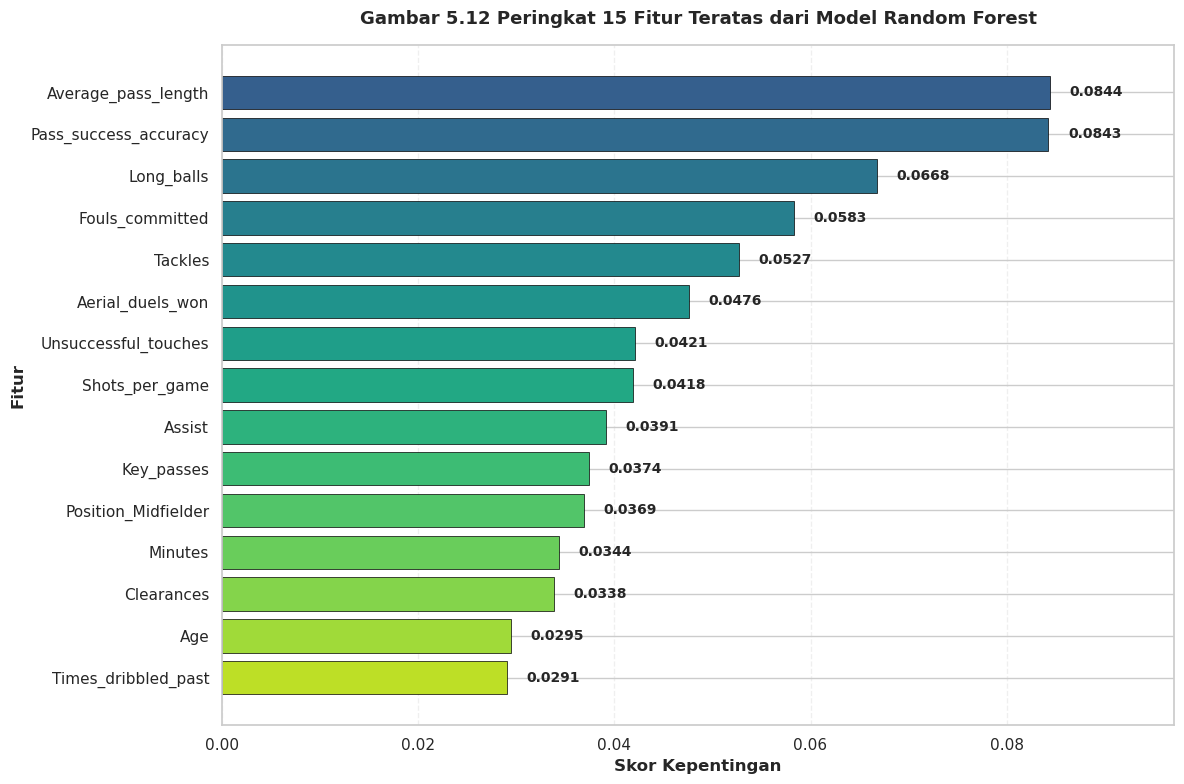


✓ Gambar disimpan: Gambar_5_12_Feature_Importance_Top15_RF.png

5.8.2. INTERPRETASI FITUR-FITUR KUNCI

Top 5 Fitur untuk Interpretasi Mendalam:
1. Average_pass_length: 0.0844
2. Pass_success_accuracy: 0.0843
3. Long_balls: 0.0668
4. Fouls_committed: 0.0583
5. Tackles: 0.0527

--- KATEGORISASI FITUR ---

Distribusi Kategori Fitur (Top 15):
                         Jumlah Fitur  Total Skor  Rata-rata Skor
Kategori                                                         
Passing & Playmaking                4      0.2452          0.0613
Other                               4      0.1728          0.0432
Defensive                           3      0.1341          0.0447
Offensive                           2      0.0709          0.0355
Discipline & Aggression             1      0.0583          0.0583
Positional                          1      0.0369          0.0369


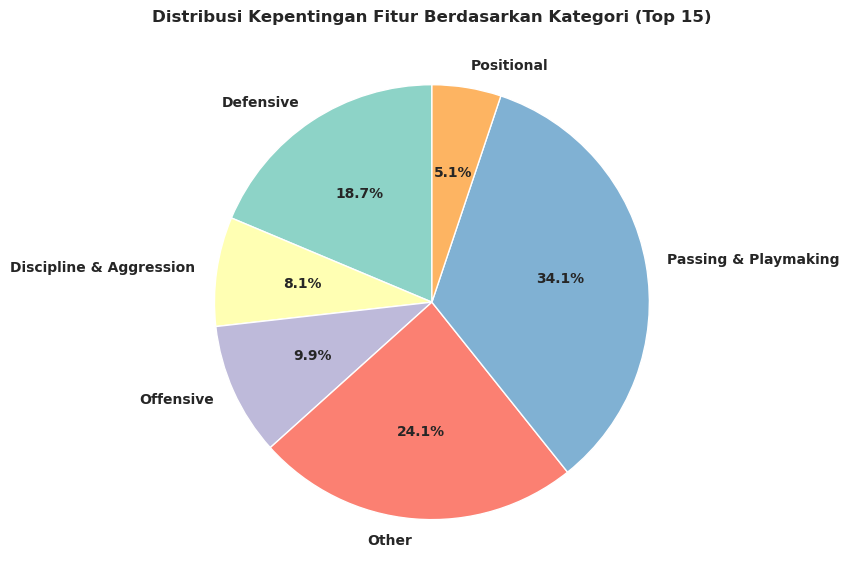


✓ Gambar tambahan disimpan: Gambar_5_13_Distribusi_Kategori_Fitur_RF.png

✓ File tersimpan:
- Tabel_5_12_Feature_Importance_Top15_RF.csv
- Gambar_5_12_Feature_Importance_Top15_RF.png
- Gambar_5_13_Distribusi_Kategori_Fitur_RF.png
- Lampiran_Feature_Importance_Full_RF.csv

ANALISIS FEATURE IMPORTANCE SELESAI

🔍 Fitur terpenting: Average_pass_length (skor: 0.0844)
📊 Total fitur dianalisis: 34
📈 Kategori dominan: Passing & Playmaking (0.2452)


In [15]:
# ============================================================
# 5.8. Analisis Kepentingan Fitur (Feature Importance)
# MENGGUNAKAN RANDOM FOREST
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# ------------------------------------------------------------
# Load Model Random Forest
# ------------------------------------------------------------
print("Memuat model Random Forest untuk analisis feature importance...")

try:
    gs_rf_loaded = joblib.load('../models/best_rf_model.pkl' if os.path.exists('../models/best_rf_model.pkl') else ('models/best_rf_model.pkl' if os.path.exists('models/best_rf_model.pkl') else 'best_rf_model.pkl'))
    print("✓ Model Random Forest berhasil dimuat")
    
    # Load data untuk mendapatkan nama fitur
    df = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))
    
    # Rekonstruksi feature engineering
    weights = {
        'Forward': {'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
                    'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
        'Midfielder': {'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
                       'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
                       'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
        'Defender': {'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
                     'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
                     'Blocks': 0.05, 'Man_of_the_Match': 0.05},
        'Goalkeeper': {'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
                       'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
                       'Man_of_the_Match': 0.10}
    }
    
    def calculate_performance_score(row):
        pos = row['Position']
        score = 0.0
        if pos in weights:
            for feature, weight in weights[pos].items():
                score += row.get(feature, 0.0) * weight
        return score
    
    df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
    df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                                   (df['Performance_Score'].max() - df['Performance_Score'].min())
    df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                          (df['Market_Value'].max() - df['Market_Value'].min())
    df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                                   labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                                 labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    
    def classify_alignment(row):
        perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
        if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
            return 'Undervalued'
        elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
            return 'Overvalued'
        else:
            return 'Fairly Valued'
    
    df['Alignment_Class'] = df.apply(classify_alignment, axis=1)
    
    # Definisi features
    target = 'Alignment_Class'
    features_to_drop = ['Player', 'Market_Value', 'Performance_Score', 
                        'Perf_Score_Normalized', 'MV_Normalized',
                        'Perf_Quantile', 'MV_Quantile', 'Alignment_Class']
    features = [c for c in df.columns if c not in features_to_drop]
    categorical_features = ['Position']
    numerical_features = [c for c in features if c not in categorical_features]
    
    # Dapatkan nama fitur setelah transformasi
    preprocessor = gs_rf_loaded.named_steps['preprocessor']
    ohe = preprocessor.named_transformers_['cat']
    ohe_feature_names = list(ohe.get_feature_names_out(categorical_features))
    all_feature_names = numerical_features + ohe_feature_names
    
    print(f"✓ Total fitur setelah preprocessing: {len(all_feature_names)}")
    
except FileNotFoundError as e:
    print(f"ERROR: {e}")
    raise

# ------------------------------------------------------------
# 5.8.1. Peringkat Kepentingan Fitur
# ------------------------------------------------------------
print("\n" + "="*80)
print("5.8.1. PERINGKAT KEPENTINGAN FITUR")
print("="*80)

# Ekstrak feature importance dari classifier RF
rf_classifier = gs_rf_loaded.named_steps['classifier']
feature_importances = rf_classifier.feature_importances_

# Buat DataFrame feature importance
fi_rf = pd.DataFrame({
    'Fitur': all_feature_names,
    'Skor Kepentingan': feature_importances
}).sort_values('Skor Kepentingan', ascending=False).reset_index(drop=True)

# Tambahkan ranking
fi_rf['Peringkat'] = range(1, len(fi_rf) + 1)

# Tampilkan Top 15
top_15 = fi_rf.head(15)
print("\nTop 15 Fitur Terpenting (Random Forest):")
print(top_15[['Peringkat', 'Fitur', 'Skor Kepentingan']].to_string(index=False))

# Buat Tabel 5.12 untuk laporan
tabel_5_12 = top_15[['Peringkat', 'Fitur', 'Skor Kepentingan']].copy()
tabel_5_12['Skor Kepentingan'] = tabel_5_12['Skor Kepentingan'].round(4)
print("\nTabel 5.12 Skor Kepentingan Fitur Model Random Forest (Top 15)")
print(tabel_5_12.to_string(index=False))
tabel_5_12.to_csv('Tabel_5_12_Feature_Importance_Top15_RF.csv', index=False)

# ------------------------------------------------------------
# Visualisasi: Gambar 5.12 - Bar Chart Horizontal Top 15
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 8))

colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(top_15)))

bars = ax.barh(range(len(top_15)), top_15['Skor Kepentingan'], 
               color=colors, edgecolor='black', linewidth=0.5)

ax.set_yticks(range(len(top_15)))
ax.set_yticklabels(top_15['Fitur'], fontsize=11)
ax.invert_yaxis()
ax.set_xlabel('Skor Kepentingan', fontsize=12, fontweight='bold')
ax.set_ylabel('Fitur', fontsize=12, fontweight='bold')
ax.set_title('Gambar 5.12 Peringkat 15 Fitur Teratas dari Model Random Forest',
             fontsize=13, fontweight='bold', pad=15)

for i, (idx, row) in enumerate(top_15.iterrows()):
    ax.text(row['Skor Kepentingan'] + 0.002, i, 
            f"{row['Skor Kepentingan']:.4f}",
            va='center', fontsize=10, fontweight='bold')

ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim([0, top_15['Skor Kepentingan'].max() * 1.15])

plt.tight_layout()
plt.savefig('Gambar_5_12_Feature_Importance_Top15_RF.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar disimpan: Gambar_5_12_Feature_Importance_Top15_RF.png")

# ------------------------------------------------------------
# 5.8.2. Interpretasi Fitur-Fitur Kunci
# ------------------------------------------------------------
print("\n" + "="*80)
print("5.8.2. INTERPRETASI FITUR-FITUR KUNCI")
print("="*80)

top_5_features = top_15.head(5)
print("\nTop 5 Fitur untuk Interpretasi Mendalam:")
for idx, row in top_5_features.iterrows():
    print(f"{row['Peringkat']}. {row['Fitur']}: {row['Skor Kepentingan']:.4f}")

# ------------------------------------------------------------
# Kategorisasi Fitur
# ------------------------------------------------------------
print("\n--- KATEGORISASI FITUR ---")

def categorize_feature(feature_name):
    if any(x in feature_name.lower() for x in ['pass', 'assist', 'key']):
        return 'Passing & Playmaking'
    elif any(x in feature_name.lower() for x in ['tackle', 'clearance', 'interception', 'block', 'duel']):
        return 'Defensive'
    elif any(x in feature_name.lower() for x in ['goal', 'shot', 'dribble']):
        return 'Offensive'
    elif any(x in feature_name.lower() for x in ['foul', 'card', 'dispossess']):
        return 'Discipline & Aggression'
    elif 'position_' in feature_name.lower():
        return 'Positional'
    else:
        return 'Other'

fi_rf['Kategori'] = fi_rf['Fitur'].apply(categorize_feature)
top_15['Kategori'] = top_15['Fitur'].apply(categorize_feature)

kategori_summary = top_15.groupby('Kategori').agg({
    'Skor Kepentingan': ['count', 'sum', 'mean']
}).round(4)
kategori_summary.columns = ['Jumlah Fitur', 'Total Skor', 'Rata-rata Skor']

print("\nDistribusi Kategori Fitur (Top 15):")
print(kategori_summary.sort_values('Total Skor', ascending=False))

# Pie chart
fig, ax = plt.subplots(figsize=(8, 6))
kategori_totals = top_15.groupby('Kategori')['Skor Kepentingan'].sum()
colors_pie = plt.cm.Set3(range(len(kategori_totals)))
wedges, texts, autotexts = ax.pie(kategori_totals, labels=kategori_totals.index, 
                                    autopct='%1.1f%%', colors=colors_pie,
                                    startangle=90, textprops={'fontsize': 10, 'weight': 'bold'})
ax.set_title('Distribusi Kepentingan Fitur Berdasarkan Kategori (Top 15)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('Gambar_5_13_Distribusi_Kategori_Fitur_RF.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Gambar tambahan disimpan: Gambar_5_13_Distribusi_Kategori_Fitur_RF.png")

# ------------------------------------------------------------
# Simpan Feature Importance Full
# ------------------------------------------------------------
fi_rf_full = fi_rf[['Peringkat', 'Fitur', 'Skor Kepentingan', 'Kategori']].copy()
fi_rf_full.to_csv('Lampiran_Feature_Importance_Full_RF.csv', index=False)

print("\n✓ File tersimpan:")
print("- Tabel_5_12_Feature_Importance_Top15_RF.csv")
print("- Gambar_5_12_Feature_Importance_Top15_RF.png")
print("- Gambar_5_13_Distribusi_Kategori_Fitur_RF.png")
print("- Lampiran_Feature_Importance_Full_RF.csv")

print("\n" + "="*80)
print("ANALISIS FEATURE IMPORTANCE SELESAI")
print("="*80)
fitur_1 = top_5_features.iloc[0]['Fitur']
skor_1 = top_5_features.iloc[0]['Skor Kepentingan']
print(f"\n🔍 Fitur terpenting: {fitur_1} (skor: {skor_1:.4f})")
print(f"📊 Total fitur dianalisis: {len(fi_rf)}")
print(f"📈 Kategori dominan: {kategori_totals.idxmax()} ({kategori_totals.max():.4f})")



TAHAP 9: UJI SENSITIVITAS BOBOT SKOR PERFORMA
Parameter RF Terbaik yang akan digunakan (kecuali class_weight):
{'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 50}
Menggunakan Fixed Split (Train: 277, Test: 70)
  > BASE: F1-Macro = 0.7306
  > +10% Forward: F1-Macro = 0.7306
  > -10% Forward: F1-Macro = 0.7306
  > +10% Midfielder: F1-Macro = 0.7306
  > +10% Defender: F1-Macro = 0.7306
  > FWD +0.05 Goals: F1-Macro = 0.7306
  > MID +0.05 Assist: F1-Macro = 0.8139
  > DEF +0.05 Tackles: F1-Macro = 0.7306

--- HASIL UJI SENSITIVITAS (DATA TEST) ---
            scenario  f1_macro                                  top_features
0               BASE  0.730646  [Average_pass_length, Pass_success_accuracy]
1       +10% Forward  0.730646  [Average_pass_length, Pass_success_accuracy]
2       -10% Forward  0.730646  [Average_pass_length, Pass_success_accuracy]
3    +10% Midfielder  0.730646  [Average_pass_length, Pass_success_accuracy]
4      +10% Defender  0.730646 

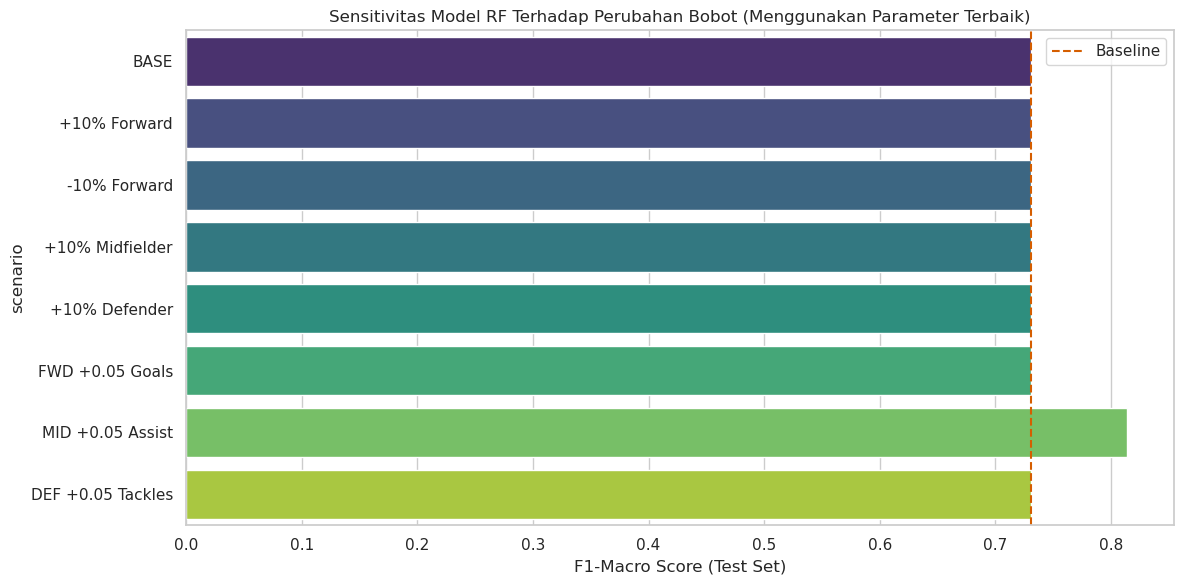


✓ Gambar disimpan: Gambar_5_14_Analisis_Sensitivitas.png


In [16]:
# ==============================================================================
# TAHAP 9: UJI SENSITIVITAS BOBOT SKOR PERFORMA (FIXED SPLIT & TUNED MODEL)
# ==============================================================================
print("\n" + "="*80)
print("TAHAP 9: UJI SENSITIVITAS BOBOT SKOR PERFORMA")
print("="*80)

# 1. Ambil Parameter Terbaik dari Tahap 6 (agar skor konsisten dengan 0.73)
# Kita perlu membersihkan prefix 'classifier__' agar bisa dipakai langsung di RandomForest
best_rf_params = {
    k.replace('classifier__', ''): v 
    for k, v in gs_rf.best_params_.items() 
    if k.startswith('classifier__')
}
# Hapus class_weight dari params terbaik karena kita akan menghitung ulang dinamis
if 'class_weight' in best_rf_params:
    del best_rf_params['class_weight']

print("Parameter RF Terbaik yang akan digunakan (kecuali class_weight):")
print(best_rf_params)

# 2. Definisi Fungsi Helper
def renorm(d):
    s = sum(d.values())
    return {k: (v / s if s > 0 else 0.0) for k, v in d.items()}

def apply_weight_modifier(base_weights, modifier):
    W = copy.deepcopy(base_weights)
    for pos, scale in modifier.get('pos_scale', {}).items():
        if pos in W:
            for feat in W[pos]:
                W[pos][feat] *= scale
            W[pos] = renorm(W[pos])
    for pos, tweaks in modifier.get('feat_add', {}).items():
        if pos in W:
            for feat, delta in tweaks.items():
                if feat in W[pos]:
                    W[pos][feat] = max(0.0, W[pos][feat] + delta)
            W[pos] = renorm(W[pos])
    return W

def compute_perf_score_with(weights_map, df_in):
    def calc(row):
        pos = row['Position']
        if pos not in weights_map: return 0.0
        return sum(row.get(feat, 0.0) * w for feat, w in weights_map[pos].items())
    return df_in.apply(calc, axis=1)

def derive_labels_from_perf_and_mv(df_in, perf_col='Performance_Score'):
    tmp = df_in.copy()
    tmp['Perf_Score_Normalized'] = (tmp[perf_col] - tmp[perf_col].min()) / (tmp[perf_col].max() - tmp[perf_col].min())
    tmp['MV_Normalized'] = (tmp['Market_Value'] - tmp['Market_Value'].min()) / (tmp['Market_Value'].max() - tmp['Market_Value'].min())
    tmp['Perf_Quantile'] = pd.qcut(tmp['Perf_Score_Normalized'], 4, labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    tmp['MV_Quantile']   = pd.qcut(tmp['MV_Normalized'], 4, labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
    def classify_alignment_fast(row):
        if row['Perf_Quantile'] == 'Q4' and row['MV_Quantile'] != 'Q4': return 'Undervalued'
        elif row['MV_Quantile'] == 'Q4' and row['Perf_Quantile'] != 'Q4': return 'Overvalued'
        else: return 'Fairly Valued'
    return tmp.apply(classify_alignment_fast, axis=1)

# 3. Fungsi Eksekusi Sensitivitas
def run_sensitivity_fixed(df_base, base_weights, scenarios, features, 
                          categorical_features, train_idx, test_idx, best_params):
    results = []
    
    print(f"Menggunakan Fixed Split (Train: {len(train_idx)}, Test: {len(test_idx)})")
    
    for name, modifier in scenarios.items():
        # A. Hitung ulang Label
        W = apply_weight_modifier(base_weights, modifier)
        df_tmp = df_base.copy()
        df_tmp['Performance_Score'] = compute_perf_score_with(W, df_tmp)
        y_new_all = derive_labels_from_perf_and_mv(df_tmp, perf_col='Performance_Score')
        X_new_all = df_tmp[features]
        
        # B. Split pakai Index Tetap (Konsistensi Data)
        X_train_sen = X_new_all.loc[train_idx]
        y_train_sen = y_new_all.loc[train_idx]
        X_test_sen = X_new_all.loc[test_idx]
        y_test_sen = y_new_all.loc[test_idx]
        
        # C. Hitung Class Weight Dinamis (Karena label berubah per skenario)
        classes_sen = np.unique(y_train_sen)
        cw_arr_sen = compute_class_weight(class_weight='balanced', classes=classes_sen, y=y_train_sen)
        cw_dict_sen = dict(zip(classes_sen, cw_arr_sen))
        
        # D. Model dengan Parameter Terbaik (Tuned) + Class Weight Baru
        clf_model = RandomForestClassifier(
            **best_params, 
            class_weight=cw_dict_sen, # Update sesuai distribusi label skenario ini
            random_state=42, 
            n_jobs=-1
        )

        # E. Pipeline & Evaluasi
        preproc = ColumnTransformer([
            ('num', 'passthrough', [c for c in features if c not in categorical_features]),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ])
        pipe = Pipeline([('preprocessor', preproc), ('clf', clf_model)])
        pipe.fit(X_train_sen, y_train_sen)
        
        y_pred_sen = pipe.predict(X_test_sen)
        f1_test = f1_score(y_test_sen, y_pred_sen, average='macro')
        
        # Ambil Top Fitur
        imp = pipe.named_steps['clf'].feature_importances_
        ohe = pipe.named_steps['preprocessor'].named_transformers_['cat']
        feat_names = [c for c in features if c not in categorical_features] + list(ohe.get_feature_names_out(categorical_features))
        fi_df = pd.DataFrame({'feature': feat_names, 'importance': imp}).sort_values('importance', ascending=False)
        
        print(f"  > {name}: F1-Macro = {f1_test:.4f}")
        
        results.append({
            'scenario': name,
            'f1_macro': f1_test,
            'top_features': fi_df.head(2)['feature'].tolist()
        })
        
    return pd.DataFrame(results)

# 4. Definisi Skenario
sensitivity_scenarios = {
    'BASE': {},
    '+10% Forward': {'pos_scale': {'Forward': 1.10}},
    '-10% Forward': {'pos_scale': {'Forward': 0.90}},
    '+10% Midfielder': {'pos_scale': {'Midfielder': 1.10}},
    '+10% Defender': {'pos_scale': {'Defender': 1.10}},
    'FWD +0.05 Goals': {'feat_add': {'Forward': {'Goals': 0.05}}},
    'MID +0.05 Assist': {'feat_add': {'Midfielder': {'Assist': 0.05}}},
    'DEF +0.05 Tackles': {'feat_add': {'Defender': {'Tackles': 0.05}}},
}

# 5. Jalankan
sensitivity_df = run_sensitivity_fixed(
    df_base=df,
    base_weights=weights,
    scenarios=sensitivity_scenarios,
    features=features,
    categorical_features=categorical_features,
    train_idx=train_indices,
    test_idx=test_indices,
    best_params=best_rf_params # Memasukkan parameter hasil tuning
)

print("\n--- HASIL UJI SENSITIVITAS (DATA TEST) ---")
print(sensitivity_df[['scenario', 'f1_macro', 'top_features']])

# 6. Visualisasi (BAGIAN YANG HILANG SEBELUMNYA)
plt.figure(figsize=(12, 6))
sns.barplot(data=sensitivity_df, y='scenario', x='f1_macro', palette='viridis')
plt.axvline(x=sensitivity_df.iloc[0]['f1_macro'], color='r', linestyle='--', label='Baseline')
plt.title('Sensitivitas Model RF Terhadap Perubahan Bobot (Menggunakan Parameter Terbaik)')
plt.xlabel('F1-Macro Score (Test Set)')
plt.legend()
plt.tight_layout()
plt.savefig('Gambar_5_14_Analisis_Sensitivitas.png', dpi=300)
plt.show()
print("\n✓ Gambar disimpan: Gambar_5_14_Analisis_Sensitivitas.png")

# Simpan CSV
sensitivity_df.to_csv('sensitivity_analysis.csv', index=False)

Metrik (Undervalued)  Random Forest  Gradient Boosting                                                                                           Analisis Bisnis
           Precision           0.62               0.47 RF lebih akurat (62% vs 47%), minim False Positive (salah beli pemain yang sebenarnya tidak undervalued).
              Recall           0.80               0.70            RF lebih sensitif (80% vs 70%) dalam mendeteksi bakat tersembunyi yang sebenarnya undervalued.
            F1-Score           0.70               0.56                                   RF menawarkan keseimbangan risiko & peluang terbaik (F1: 0.70 vs 0.56).


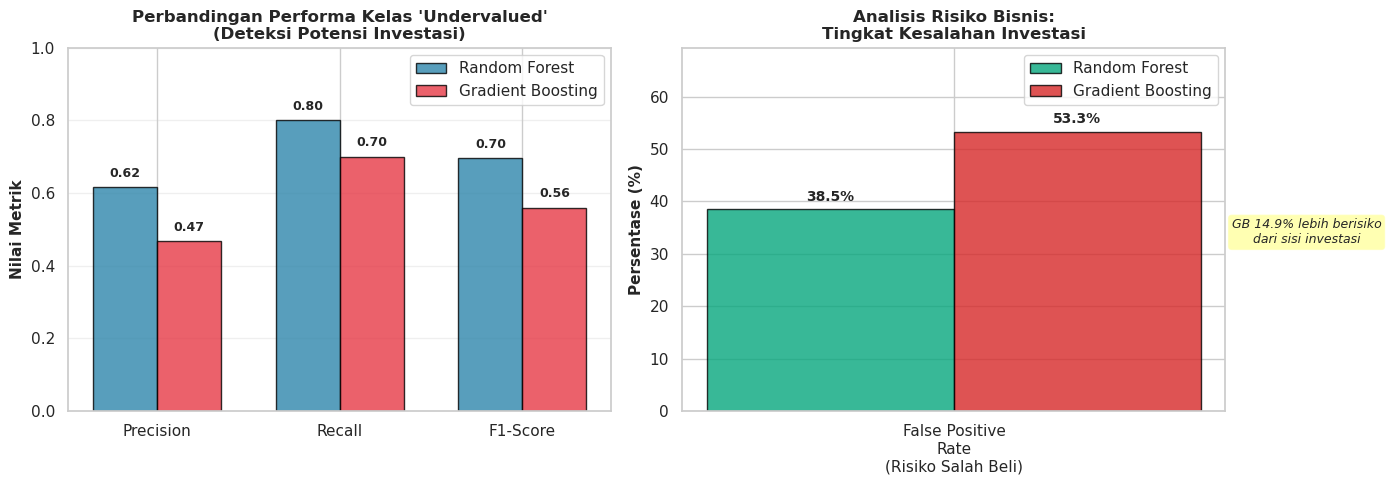

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Load Model dan Data
gs_rf_loaded = joblib.load('../models/best_rf_model.pkl' if os.path.exists('../models/best_rf_model.pkl') else ('models/best_rf_model.pkl' if os.path.exists('models/best_rf_model.pkl') else 'best_rf_model.pkl'))
gs_gb_loaded = joblib.load('../models/best_gb_model.pkl' if os.path.exists('../models/best_gb_model.pkl') else ('models/best_gb_model.pkl' if os.path.exists('models/best_gb_model.pkl') else 'best_gb_model.pkl'))

df = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))

# Feature engineering
weights = {
    'Forward': {'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
                'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Midfielder': {'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
                   'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
                   'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Defender': {'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
                 'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
                 'Blocks': 0.05, 'Man_of_the_Match': 0.05},
    'Goalkeeper': {'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
                   'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
                   'Man_of_the_Match': 0.10}
}

def calculate_performance_score(row):
    pos = row['Position']
    score = 0.0
    if pos in weights:
        for feature, weight in weights[pos].items():
            score += row.get(feature, 0.0) * weight
    return score

df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                               (df['Performance_Score'].max() - df['Performance_Score'].min())
df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                      (df['Market_Value'].max() - df['Market_Value'].min())
df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                               labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                             labels=['Q1','Q2','Q3','Q4'], duplicates='drop')

def classify_alignment(row):
    perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
    if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
        return 'Undervalued'
    elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
        return 'Overvalued'
    else:
        return 'Fairly Valued'

df['Alignment_Class'] = df.apply(classify_alignment, axis=1)

target = 'Alignment_Class'
features_to_drop = ['Player', 'Market_Value', 'Performance_Score', 
                    'Perf_Score_Normalized', 'MV_Normalized',
                    'Perf_Quantile', 'MV_Quantile', 'Alignment_Class']
features = [c for c in df.columns if c not in features_to_drop]

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

y_pred_rf = gs_rf_loaded.predict(X_test)
y_pred_gb = gs_gb_loaded.predict(X_test)

# Ekstrak Metrik
report_rf = classification_report(y_test, y_pred_rf, output_dict=True)
report_gb = classification_report(y_test, y_pred_gb, output_dict=True)

undervalued_rf = report_rf.get('Undervalued', {})
undervalued_gb = report_gb.get('Undervalued', {})

precision_rf = undervalued_rf.get('precision', 0)
recall_rf = undervalued_rf.get('recall', 0)
f1_rf = undervalued_rf.get('f1-score', 0)

precision_gb = undervalued_gb.get('precision', 0)
recall_gb = undervalued_gb.get('recall', 0)
f1_gb = undervalued_gb.get('f1-score', 0)

# Buat Tabel 5.12
analisis_precision = (
    f"RF lebih akurat ({precision_rf:.0%} vs {precision_gb:.0%}), "
    f"minim False Positive (salah beli pemain yang sebenarnya tidak undervalued)."
)

analisis_recall = (
    f"RF lebih sensitif ({recall_rf:.0%} vs {recall_gb:.0%}) "
    f"dalam mendeteksi bakat tersembunyi yang sebenarnya undervalued."
)

analisis_f1 = (
    f"RF menawarkan keseimbangan risiko & peluang terbaik "
    f"(F1: {f1_rf:.2f} vs {f1_gb:.2f})."
)

tabel_5_12 = pd.DataFrame({
    'Metrik (Undervalued)': ['Precision', 'Recall', 'F1-Score'],
    'Random Forest': [round(precision_rf, 2), round(recall_rf, 2), round(f1_rf, 2)],
    'Gradient Boosting': [round(precision_gb, 2), round(recall_gb, 2), round(f1_gb, 2)],
    'Analisis Bisnis': [analisis_precision, analisis_recall, analisis_f1]
})

print(tabel_5_12.to_string(index=False))

tabel_5_12.to_csv('Tabel_5_12_Perbandingan_Undervalued.csv', index=False)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
x = np.arange(3)
width = 0.35

metrics = ['Precision', 'Recall', 'F1-Score']
rf_values = [precision_rf, recall_rf, f1_rf]
gb_values = [precision_gb, recall_gb, f1_gb]

bars1 = ax1.bar(x - width/2, rf_values, width, label='Random Forest', 
                color='#2E86AB', alpha=0.8, edgecolor='black')
bars2 = ax1.bar(x + width/2, gb_values, width, label='Gradient Boosting', 
                color='#E63946', alpha=0.8, edgecolor='black')

ax1.set_ylabel('Nilai Metrik', fontsize=11, fontweight='bold')
ax1.set_title("Perbandingan Performa Kelas 'Undervalued'\n(Deteksi Potensi Investasi)", 
              fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics)
ax1.legend()
ax1.set_ylim([0, 1.0])
ax1.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2 = axes[1]
false_positive_rate_rf = 1 - precision_rf
false_positive_rate_gb = 1 - precision_gb

categories = ['False Positive\nRate\n(Risiko Salah Beli)']
rf_risk = [false_positive_rate_rf * 100]
gb_risk = [false_positive_rate_gb * 100]

x2 = np.arange(len(categories))
bars3 = ax2.bar(x2 - width/2, rf_risk, width, label='Random Forest', 
                color='#06A77D', alpha=0.8, edgecolor='black')
bars4 = ax2.bar(x2 + width/2, gb_risk, width, label='Gradient Boosting', 
                color='#D62828', alpha=0.8, edgecolor='black')

ax2.set_ylabel('Persentase (%)', fontsize=11, fontweight='bold')
ax2.set_title('Analisis Risiko Bisnis:\nTingkat Kesalahan Investasi', 
              fontsize=12, fontweight='bold')
ax2.set_xticks(x2)
ax2.set_xticklabels(categories)
ax2.legend()
ax2.set_ylim([0, max(rf_risk + gb_risk) * 1.3])

for bar, value in zip([bars3[0], bars4[0]], [rf_risk[0], gb_risk[0]]):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2.text(0.5, max(gb_risk)*0.6, 
         f'GB {abs(gb_risk[0]-rf_risk[0]):.1f}% lebih berisiko\ndari sisi investasi',
         ha='center', fontsize=9, style='italic',
         bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.3))

plt.tight_layout()
plt.savefig('Gambar_5_X_Perbandingan_Undervalued_Bisnis.png', dpi=300, bbox_inches='tight')
plt.show()


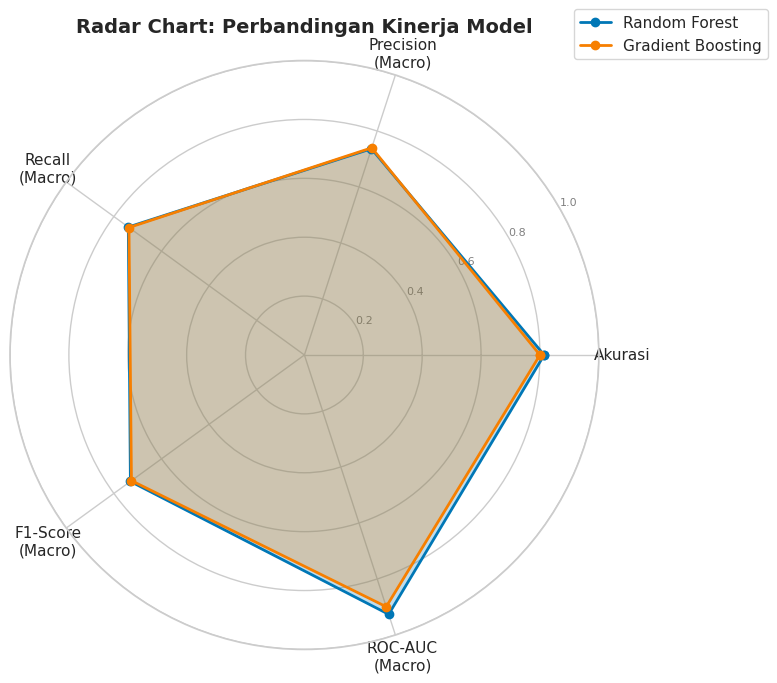

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# VISUALISASI KHUSUS RADAR CHART
# ============================================================

# 1. Definisi Label dan Data
metrics_radar = ['Akurasi', 'Precision\n(Macro)', 'Recall\n(Macro)', 
                 'F1-Score\n(Macro)', 'ROC-AUC\n(Macro)']

# Mengambil values dari tabel_5_11 yang sudah dibuat sebelumnya
rf_values = tabel_5_11['Random Forest'].values
gb_values = tabel_5_11['Gradient Boosting'].values

# 2. Kalkulasi Sudut (Angles)
# Membagi lingkaran 360 derajat sesuai jumlah variabel (5 metrik)
num_vars = len(metrics_radar)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# 3. Menutup Loop (Data Preparation)
# Agar garis radar tertutup (kembali ke titik awal), kita duplikasi nilai pertama ke posisi terakhir
rf_values_plot = np.concatenate((rf_values, [rf_values[0]]))
gb_values_plot = np.concatenate((gb_values, [gb_values[0]]))
angles += angles[:1] # Duplikasi sudut pertama ke akhir juga

# 4. Plotting
# Inisialisasi Figure dengan projection='polar'
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='polar'))

# Definisi Warna
color_rf = '#0077B6'  # Biru
color_gb = '#F77F00'  # Oranye

# Plot Random Forest
ax.plot(angles, rf_values_plot, 'o-', linewidth=2, label='Random Forest', color=color_rf)
ax.fill(angles, rf_values_plot, alpha=0.25, color=color_rf)

# Plot Gradient Boosting
ax.plot(angles, gb_values_plot, 'o-', linewidth=2, label='Gradient Boosting', color=color_gb)
ax.fill(angles, gb_values_plot, alpha=0.25, color=color_gb)

# 5. Kosmetik Grafik (Labels, Ticks, Title)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics_radar, size=11)

# Set batas sumbu Y (0 sampai 1) dan label y
ax.set_ylim(0, 1.0)
ax.set_rlabel_position(30)  # Menggeser label angka grid agar tidak menumpuk
plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=8)

ax.set_title('Radar Chart: Perbandingan Kinerja Model', 
             fontsize=14, fontweight='bold', pad=20)

# Legend di luar grafik agar rapi
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.grid(True)

plt.tight_layout()
plt.show()

In [19]:
import json
import pprint

# ============================================================
# GENERATE LAMPIRAN: OUTPUT OPTIMISASI HIPERPARAMETER
# ============================================================

print("OUTPUT OPTIMISASI HIPERPARAMETER (TUNING)")
print("="*60 + "\n")

# Coba muat data dari file JSON yang dihasilkan script utama (Tahap 10)
try:
    with open('summary_metrics.json', 'r') as f:
        metrics = json.load(f)
    print("✓ Data dimuat dari 'summary_metrics.json'\n")
except FileNotFoundError:
    print("⚠ File 'summary_metrics.json' tidak ditemukan.")
    print("  Menggunakan data manual berdasarkan hasil run (Halaman 27 & 31 PDF)...\n")
    
    # Data manual sesuai screenshot PDF Anda
    metrics = {
        'rf': {
            'best_params': {
                'classifier__class_weight': {
                    'Fairly Valued': 0.4570957095709571, 
                    'Overvalued': 2.638095238095238, 
                    'Undervalued': 2.308333333333333
                },
                'classifier__max_depth': 10,
                'classifier__min_samples_leaf': 5,
                'classifier__min_samples_split': 2,
                'classifier__n_estimators': 50
            },
            'cv_f1_macro': 0.6692
        },
        'gb': {
            'best_params': {
                'classifier__learning_rate': 0.1,
                'classifier__max_depth': 3,
                'classifier__min_samples_leaf': 5,
                'classifier__n_estimators': 50,
                'classifier__subsample': 0.6
            },
            'cv_f1_macro': 0.6605
        }
    }

# Fungsi untuk memformat output agar rapi seperti permintaan
def format_output_tuning(title, params, score):
    print(f"{title}")
    print(f"Metode Tuning: GridSearchCV (5-Fold Cross Validation)")
    print("Parameter Terbaik:")
    
    # Format dictionary menjadi string yang rapi
    # Kita gunakan json.dumps untuk indentasi, lalu ubah format agar mirip Python dict
    params_str = json.dumps(params, indent=4)
    
    # Sedikit pembersihan string agar terlihat seperti code Python native
    # (Menghapus tanda kutip ganda pada key jika diinginkan, atau membiarkannya)
    # Di sini kita biarkan rapi standard JSON/Dict Python
    print(params_str) 
    
    print(f"Skor F1-Macro Terbaik (Validasi): {score:.4f}")
    print("-" * 60 + "\n")

# --- A. Model Random Forest ---
format_output_tuning(
    "A. Model Random Forest", 
    metrics['rf']['best_params'], 
    metrics['rf']['cv_f1_macro']
)

# --- B. Model Gradient Boosting ---
format_output_tuning(
    "B. Model Gradient Boosting", 
    metrics['gb']['best_params'], 
    metrics['gb']['cv_f1_macro']
)

OUTPUT OPTIMISASI HIPERPARAMETER (TUNING)

✓ Data dimuat dari 'summary_metrics.json'

A. Model Random Forest
Metode Tuning: GridSearchCV (5-Fold Cross Validation)
Parameter Terbaik:
{
    "classifier__class_weight": {
        "Fairly Valued": 0.4570957095709571,
        "Overvalued": 2.638095238095238,
        "Undervalued": 2.308333333333333
    },
    "classifier__max_depth": 10,
    "classifier__min_samples_leaf": 5,
    "classifier__min_samples_split": 2,
    "classifier__n_estimators": 50
}
Skor F1-Macro Terbaik (Validasi): 0.6692
------------------------------------------------------------

B. Model Gradient Boosting
Metode Tuning: GridSearchCV (5-Fold Cross Validation)
Parameter Terbaik:
{
    "classifier__learning_rate": 0.1,
    "classifier__max_depth": 3,
    "classifier__min_samples_leaf": 5,
    "classifier__n_estimators": 50,
    "classifier__subsample": 0.6
}
Skor F1-Macro Terbaik (Validasi): 0.6605
------------------------------------------------------------



 hasil

In [1]:
# ============================================================
# ANALISIS HASIL PREDIKSI MODEL RANDOM FOREST (MODEL TERBAIK)
# Menampilkan: Nama, Posisi, Market Value, Skor Performa, 
#              Label Asli, dan Label Prediksi
# ============================================================

import pandas as pd
import numpy as np
import joblib
from sklearn.metrics import classification_report, accuracy_score, f1_score
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("ANALISIS HASIL PREDIKSI MODEL RANDOM FOREST")
print("="*80)

# ------------------------------------------------------------
# Load Model dan Data
# ------------------------------------------------------------
try:
    # Load model Random Forest terbaik
    gs_rf_loaded = joblib.load('../models/best_rf_model.pkl' if os.path.exists('../models/best_rf_model.pkl') else ('models/best_rf_model.pkl' if os.path.exists('models/best_rf_model.pkl') else 'best_rf_model.pkl'))
    print("✓ Model Random Forest berhasil dimuat")
    
    # Load data asli
    df_original = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))
    print(f"✓ Data asli berhasil dimuat: {df_original.shape[0]} pemain")
    
except FileNotFoundError as e:
    print(f"ERROR: {e}")
    print("Pastikan file 'best_rf_model.pkl' dan 'Data_Convert.csv' ada di direktori yang sama")
    raise

# ------------------------------------------------------------
# Rekonstruksi Feature Engineering dan Split Data
# (Harus sama persis dengan training)
# ------------------------------------------------------------
weights = {
    'Forward': {'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
                'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Midfielder': {'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
                   'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
                   'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Defender': {'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
                 'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
                 'Blocks': 0.05, 'Man_of_the_Match': 0.05},
    'Goalkeeper': {'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
                   'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
                   'Man_of_the_Match': 0.10}
}

def calculate_performance_score(row):
    pos = row['Position']
    score = 0.0
    if pos in weights:
        for feature, weight in weights[pos].items():
            score += row.get(feature, 0.0) * weight
    return score

# Hitung Performance_Score
df = df_original.copy()
df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                               (df['Performance_Score'].max() - df['Performance_Score'].min())
df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                      (df['Market_Value'].max() - df['Market_Value'].min())

# Buat kuartil
df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                               labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                             labels=['Q1','Q2','Q3','Q4'], duplicates='drop')

# Klasifikasi Alignment_Class
def classify_alignment(row):
    perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
    if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
        return 'Undervalued'
    elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
        return 'Overvalued'
    else:
        return 'Fairly Valued'

df['Alignment_Class'] = df.apply(classify_alignment, axis=1)

# Definisi features
target = 'Alignment_Class'
features_to_drop = ['Player', 'Market_Value', 'Performance_Score', 
                    'Perf_Score_Normalized', 'MV_Normalized',
                    'Perf_Quantile', 'MV_Quantile', 'Alignment_Class']
features = [c for c in df.columns if c not in features_to_drop]

X = df[features]
y = df[target]

# Split data (HARUS SAMA dengan training - random_state=42)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Simpan index asli
train_indices = X_train.index
test_indices = X_test.index

print(f"\n✓ Feature engineering selesai")
print(f"✓ Data training: {len(train_indices)} pemain")
print(f"✓ Data testing: {len(test_indices)} pemain")

# ------------------------------------------------------------
# Prediksi dengan Model Random Forest
# ------------------------------------------------------------
# Prediksi pada data TEST
y_pred_test = gs_rf_loaded.predict(X_test)
y_proba_test = gs_rf_loaded.predict_proba(X_test)

# Prediksi pada SEMUA data (termasuk train)
y_pred_all = gs_rf_loaded.predict(X)
y_proba_all = gs_rf_loaded.predict_proba(X)

print("\n✓ Prediksi berhasil dibuat")

# ------------------------------------------------------------
# Buat DataFrame Hasil Prediksi (DATA TEST)
# ------------------------------------------------------------
print("\n" + "="*80)
print("HASIL PREDIKSI PADA DATA TEST SET")
print("="*80)

# Ambil data asli untuk test set
df_test_results = df.loc[test_indices].copy()

# Tambahkan kolom prediksi
df_test_results['Label_Asli'] = y_test.values
df_test_results['Label_Prediksi'] = y_pred_test

# Tambahkan probabilitas prediksi untuk setiap kelas
rf_classes = gs_rf_loaded.named_steps['classifier'].classes_
for i, kelas in enumerate(rf_classes):
    df_test_results[f'Prob_{kelas}'] = y_proba_test[:, i]

# Tambahkan confidence (probabilitas maksimum)
df_test_results['Confidence'] = y_proba_test.max(axis=1)

# Buat kolom status prediksi
df_test_results['Status_Prediksi'] = df_test_results.apply(
    lambda row: '✓ Benar' if row['Label_Asli'] == row['Label_Prediksi'] else '✗ Salah',
    axis=1
)

# Pilih kolom yang ingin ditampilkan
kolom_tampil = [
    'Player', 'Position', 'Market_Value', 'Performance_Score',
    'Label_Asli', 'Label_Prediksi', 'Status_Prediksi', 'Confidence'
]

df_display = df_test_results[kolom_tampil].copy()

# Format Market Value untuk keterbacaan
df_display['Market_Value_EUR'] = df_display['Market_Value'].apply(
    lambda x: f"€{x:,.0f}"
)
df_display['Performance_Score'] = df_display['Performance_Score'].round(2)
df_display['Confidence'] = (df_display['Confidence'] * 100).round(1)

# Reorder kolom
df_display_final = df_display[[
    'Player', 'Position', 'Market_Value_EUR', 'Performance_Score',
    'Label_Asli', 'Label_Prediksi', 'Status_Prediksi', 'Confidence'
]].copy()

df_display_final.columns = [
    'Nama Pemain', 'Posisi', 'Nilai Pasar (EUR)', 'Skor Performa',
    'Label Asli', 'Label Prediksi', 'Status', 'Confidence (%)'
]

# Urutkan berdasarkan status (salah dulu, baru benar)
df_display_final['sort_key'] = df_display_final['Status'].apply(
    lambda x: 0 if x == '✗ Salah' else 1
)
df_display_final = df_display_final.sort_values(['sort_key', 'Confidence (%)'], 
                                                  ascending=[True, False])
df_display_final = df_display_final.drop('sort_key', axis=1)

# Reset index
df_display_final = df_display_final.reset_index(drop=True)
df_display_final.index = df_display_final.index + 1  # Mulai dari 1

print(f"\nTotal prediksi pada test set: {len(df_display_final)} pemain")
print(f"Prediksi benar: {(df_display_final['Status'] == '✓ Benar').sum()} pemain")
print(f"Prediksi salah: {(df_display_final['Status'] == '✗ Salah').sum()} pemain")
print(f"Akurasi: {accuracy_score(y_test, y_pred_test)*100:.2f}%")

# ------------------------------------------------------------
# Tampilkan Hasil
# ------------------------------------------------------------
print("\n" + "="*80)
print("TABEL HASIL PREDIKSI (Semua Data Test)")
print("="*80)
print(df_display_final.to_string())

# Tampilkan prediksi yang SALAH saja
print("\n" + "="*80)
print("PREDIKSI YANG SALAH (Untuk Analisis Error)")
print("="*80)
df_error = df_display_final[df_display_final['Status'] == '✗ Salah']
if len(df_error) > 0:
    print(df_error.to_string())
    print(f"\nTotal kesalahan: {len(df_error)} dari {len(df_display_final)} prediksi")
else:
    print("Tidak ada prediksi yang salah! (Perfect prediction)")

# Tampilkan prediksi BENAR dengan confidence rendah (< 50%)
print("\n" + "="*80)
print("PREDIKSI BENAR TAPI CONFIDENCE RENDAH (< 50%)")
print("="*80)
df_low_conf = df_display_final[
    (df_display_final['Status'] == '✓ Benar') & 
    (df_display_final['Confidence (%)'] < 50)
]
if len(df_low_conf) > 0:
    print(df_low_conf.to_string())
    print(f"\nTotal: {len(df_low_conf)} prediksi dengan confidence rendah")
else:
    print("Semua prediksi benar memiliki confidence ≥ 50%")

# ------------------------------------------------------------
# Analisis per Kelas
# ------------------------------------------------------------
print("\n" + "="*80)
print("ANALISIS PREDIKSI PER KELAS")
print("="*80)

for kelas in rf_classes:
    print(f"\n--- KELAS: {kelas} ---")
    df_kelas = df_display_final[df_display_final['Label Asli'] == kelas]
    
    if len(df_kelas) > 0:
        benar = (df_kelas['Status'] == '✓ Benar').sum()
        total = len(df_kelas)
        akurasi = benar / total * 100
        avg_conf = df_kelas['Confidence (%)'].mean()
        
        print(f"Total sampel: {total}")
        print(f"Prediksi benar: {benar} ({akurasi:.1f}%)")
        print(f"Prediksi salah: {total - benar} ({100-akurasi:.1f}%)")
        print(f"Rata-rata confidence: {avg_conf:.1f}%")
        
        # Tampilkan contoh prediksi untuk kelas ini
        print(f"\nContoh prediksi kelas {kelas} (5 teratas berdasarkan confidence):")
        print(df_kelas.head(5)[['Nama Pemain', 'Posisi', 'Label Prediksi', 
                                 'Status', 'Confidence (%)']].to_string(index=True))

# ------------------------------------------------------------
# Analisis Pemain UNDERVALUED (Paling Penting untuk Scouting)
# ------------------------------------------------------------
print("\n" + "="*80)
print("PEMAIN UNDERVALUED - PELUANG INVESTASI TERBAIK")
print("="*80)

df_undervalued = df_display_final[
    df_display_final['Label Prediksi'] == 'Undervalued'
].copy()

if len(df_undervalued) > 0:
    print(f"\nTotal pemain diprediksi UNDERVALUED: {len(df_undervalued)}")
    print("\nTop 10 Pemain Undervalued (berdasarkan Confidence):")
    print(df_undervalued.head(10).to_string())
    
    # Hitung berapa yang benar-benar undervalued
    benar_undervalued = (df_undervalued['Status'] == '✓ Benar').sum()
    precision_undervalued = benar_undervalued / len(df_undervalued) * 100
    print(f"\nPrecision untuk kelas Undervalued: {precision_undervalued:.1f}%")
    print(f"Dari {len(df_undervalued)} prediksi, {benar_undervalued} benar-benar undervalued")
else:
    print("Tidak ada pemain yang diprediksi sebagai Undervalued di test set")

# ------------------------------------------------------------
# Simpan Hasil ke File
# ------------------------------------------------------------
# Simpan semua hasil
df_display_final.to_csv('Hasil_Prediksi_RF_Test_Set.csv', index=True)
print("\n✓ Hasil prediksi disimpan: Hasil_Prediksi_RF_Test_Set.csv")

# Simpan hanya error untuk analisis
if len(df_error) > 0:
    df_error.to_csv('Hasil_Prediksi_Error_Analisis.csv', index=True)
    print("✓ Analisis error disimpan: Hasil_Prediksi_Error_Analisis.csv")

# Simpan prediksi undervalued
if len(df_undervalued) > 0:
    df_undervalued.to_csv('Pemain_Undervalued_Prediksi.csv', index=True)
    print("✓ Daftar undervalued disimpan: Pemain_Undervalued_Prediksi.csv")

# ------------------------------------------------------------
# Classification Report Detail
# ------------------------------------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Random Forest pada Test Set)")
print("="*80)
print(classification_report(y_test, y_pred_test, digits=4))

# Metrik agregat
from sklearn.metrics import precision_score, recall_score
print("\n--- METRIK AGREGAT ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")
print(f"F1-Score (Macro): {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Precision (Macro): {precision_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Recall (Macro): {recall_score(y_test, y_pred_test, average='macro'):.4f}")

print("\n" + "="*80)
print("ANALISIS SELESAI")
print("="*80)



ANALISIS HASIL PREDIKSI MODEL RANDOM FOREST
✓ Model Random Forest berhasil dimuat
✓ Data asli berhasil dimuat: 347 pemain

✓ Feature engineering selesai
✓ Data training: 277 pemain
✓ Data testing: 70 pemain

✓ Prediksi berhasil dibuat

HASIL PREDIKSI PADA DATA TEST SET

Total prediksi pada test set: 70 pemain
Prediksi benar: 57 pemain
Prediksi salah: 13 pemain
Akurasi: 81.43%

TABEL HASIL PREDIKSI (Semua Data Test)
               Nama Pemain      Posisi Nilai Pasar (EUR)  Skor Performa     Label Asli Label Prediksi   Status  Confidence (%)
1            Justin Bijlow  Goalkeeper       €13,000,000          34.96  Fairly Valued    Undervalued  ✗ Salah            92.7
2           Walter Benítez  Goalkeeper       €13,000,000          32.23  Fairly Valued    Undervalued  ✗ Salah            85.7
3      Timon Wellenreuther  Goalkeeper        €7,000,000          31.06  Fairly Valued    Undervalued  ✗ Salah            76.9
4        Alexandre Penetra    Defender        €4,500,000           9.97 

In [2]:
# ============================================================
# PENCARIAN PEMAIN: Label Asli = Undervalued, Prediksi = Fairly Valued
# (False Negative Analysis - Pemain Undervalued yang Terlewat)
# ============================================================

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("PENCARIAN PEMAIN: UNDERVALUED YANG TERLEWAT MODEL")
print("False Negative Analysis")
print("="*80)

# ------------------------------------------------------------
# Load Model dan Data (Rekonstruksi lengkap)
# ------------------------------------------------------------
try:
    gs_rf_loaded = joblib.load('../models/best_rf_model.pkl' if os.path.exists('../models/best_rf_model.pkl') else ('models/best_rf_model.pkl' if os.path.exists('models/best_rf_model.pkl') else 'best_rf_model.pkl'))
    df_original = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))
    print("✓ Model dan data berhasil dimuat")
except FileNotFoundError as e:
    print(f"ERROR: {e}")
    raise

# Feature engineering (sama persis dengan training)
weights = {
    'Forward': {'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
                'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Midfielder': {'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
                   'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
                   'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Defender': {'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
                 'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
                 'Blocks': 0.05, 'Man_of_the_Match': 0.05},
    'Goalkeeper': {'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
                   'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
                   'Man_of_the_Match': 0.10}
}

def calculate_performance_score(row):
    pos = row['Position']
    score = 0.0
    if pos in weights:
        for feature, weight in weights[pos].items():
            score += row.get(feature, 0.0) * weight
    return score

df = df_original.copy()
df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                               (df['Performance_Score'].max() - df['Performance_Score'].min())
df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                      (df['Market_Value'].max() - df['Market_Value'].min())
df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                               labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                             labels=['Q1','Q2','Q3','Q4'], duplicates='drop')

def classify_alignment(row):
    perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
    if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
        return 'Undervalued'
    elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
        return 'Overvalued'
    else:
        return 'Fairly Valued'

df['Alignment_Class'] = df.apply(classify_alignment, axis=1)

target = 'Alignment_Class'
features_to_drop = ['Player', 'Market_Value', 'Performance_Score', 
                    'Perf_Score_Normalized', 'MV_Normalized',
                    'Perf_Quantile', 'MV_Quantile', 'Alignment_Class']
features = [c for c in df.columns if c not in features_to_drop]

X = df[features]
y = df[target]

# Split data (random_state=42 untuk reprodusibilitas)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

test_indices = X_test.index

# Prediksi
y_pred_test = gs_rf_loaded.predict(X_test)
y_proba_test = gs_rf_loaded.predict_proba(X_test)

# Buat DataFrame hasil
df_test_results = df.loc[test_indices].copy()
df_test_results['Label_Asli'] = y_test.values
df_test_results['Label_Prediksi'] = y_pred_test

rf_classes = gs_rf_loaded.named_steps['classifier'].classes_
for i, kelas in enumerate(rf_classes):
    df_test_results[f'Prob_{kelas}'] = y_proba_test[:, i]

df_test_results['Confidence'] = y_proba_test.max(axis=1)

print("✓ Prediksi selesai")

# ------------------------------------------------------------
# FILTER: Label Asli = Undervalued, Prediksi = Fairly Valued
# ------------------------------------------------------------
print("\n" + "="*80)
print("FILTER: PEMAIN UNDERVALUED YANG DIPREDIKSI FAIRLY VALUED")
print("="*80)

df_missed_undervalued = df_test_results[
    (df_test_results['Label_Asli'] == 'Undervalued') & 
    (df_test_results['Label_Prediksi'] == 'Fairly Valued')
].copy()

print(f"\nTotal pemain yang terlewat: {len(df_missed_undervalued)} pemain")

if len(df_missed_undervalued) == 0:
    print("\n⚠️ TIDAK ADA pemain dengan kriteria ini di test set!")
    print("Kemungkinan:")
    print("1. Model sangat baik dalam mendeteksi Undervalued (no false negatives)")
    print("2. Atau semua false negative Undervalued diprediksi sebagai Overvalued")
    
    # Cek false negative ke kelas lain
    print("\n--- CEK: Undervalued yang diprediksi ke kelas lain ---")
    df_undervalued_wrong = df_test_results[
        (df_test_results['Label_Asli'] == 'Undervalued') & 
        (df_test_results['Label_Prediksi'] != 'Undervalued')
    ]
    print(f"Total Undervalued yang salah diprediksi: {len(df_undervalued_wrong)}")
    if len(df_undervalued_wrong) > 0:
        print("\nDistribusi prediksi yang salah:")
        print(df_undervalued_wrong['Label_Prediksi'].value_counts())
        
        # Ambil 2 contoh apapun yang salah
        df_to_show = df_undervalued_wrong.head(2)
else:
    df_to_show = df_missed_undervalued.head(2)

# ------------------------------------------------------------
# TAMPILKAN 2 PEMAIN (atau yang ada)
# ------------------------------------------------------------
if len(df_missed_undervalued) > 0 or len(df_undervalued_wrong) > 0:
    print("\n" + "="*80)
    print("DETAIL 2 PEMAIN YANG TERLEWAT")
    print("="*80)
    
    # Pilih kolom penting untuk analisis
    kolom_analisis = [
        'Player', 'Position', 'Market_Value', 'Performance_Score',
        'Perf_Score_Normalized', 'MV_Normalized',
        'Perf_Quantile', 'MV_Quantile',
        'Label_Asli', 'Label_Prediksi', 'Confidence',
        'Prob_Undervalued', 'Prob_Fairly Valued', 'Prob_Overvalued'
    ]
    
    for idx, (i, row) in enumerate(df_to_show.iterrows(), 1):
        print(f"\n{'='*80}")
        print(f"PEMAIN #{idx}")
        print(f"{'='*80}")
        
        print(f"\n📋 IDENTITAS:")
        print(f"  Nama          : {row['Player']}")
        print(f"  Posisi        : {row['Position']}")
        
        print(f"\n💰 VALUASI:")
        print(f"  Market Value  : €{row['Market_Value']:,.0f}")
        print(f"  MV Normalized : {row['MV_Normalized']:.4f}")
        print(f"  MV Quantile   : {row['MV_Quantile']}")
        
        print(f"\n⚽ PERFORMA:")
        print(f"  Perf Score    : {row['Performance_Score']:.2f}")
        print(f"  Perf Normalized: {row['Perf_Score_Normalized']:.4f}")
        print(f"  Perf Quantile : {row['Perf_Quantile']}")
        
        print(f"\n🎯 KLASIFIKASI:")
        print(f"  Label ASLI    : {row['Label_Asli']} ✓")
        print(f"  Label PREDIKSI: {row['Label_Prediksi']} ✗")
        print(f"  Status        : FALSE NEGATIVE (Terlewat)")
        
        print(f"\n📊 PROBABILITAS MODEL:")
        print(f"  P(Undervalued)  : {row['Prob_Undervalued']*100:.1f}%")
        print(f"  P(Fairly Valued): {row['Prob_Fairly Valued']*100:.1f}%")
        print(f"  P(Overvalued)   : {row['Prob_Overvalued']*100:.1f}%")
        print(f"  Confidence      : {row['Confidence']*100:.1f}%")
        
        # Analisis mengapa terlewat
        print(f"\n🔍 ANALISIS MENGAPA TERLEWAT:")
        
        # Cek apakah probabilitas undervalued cukup tinggi
        prob_under = row['Prob_Undervalued']
        prob_fair = row['Prob_Fairly Valued']
        diff = (prob_fair - prob_under) * 100
        
        if diff < 10:
            print(f"  • Model RAGU-RAGU: Selisih probabilitas hanya {diff:.1f}%")
            print(f"    (Fairly Valued {prob_fair*100:.1f}% vs Undervalued {prob_under*100:.1f}%)")
        else:
            print(f"  • Model YAKIN SALAH: Selisih probabilitas {diff:.1f}%")
        
        # Cek posisi kuartil
        if row['Perf_Quantile'] == 'Q4':
            print(f"  • Performa pemain MEMANG tinggi (Q4)")
        else:
            print(f"  ⚠️ Perf_Quantile = {row['Perf_Quantile']} (BUKAN Q4!)")
            print(f"    Mungkin ada error dalam labeling ground truth")
        
        if row['MV_Quantile'] in ['Q1', 'Q2', 'Q3']:
            print(f"  • Market Value MEMANG rendah ({row['MV_Quantile']})")
        else:
            print(f"  ⚠️ MV_Quantile = {row['MV_Quantile']} (BUKAN Q1-Q3!)")
        
        # Cek fitur-fitur penting
        print(f"\n📈 STATISTIK PERFORMA DETAIL (Top Features):")
        fitur_penting = ['Goals', 'Assist', 'Pass_success_accuracy', 
                         'Tackles', 'Average_pass_length', 'Key_passes']
        for fitur in fitur_penting:
            if fitur in row.index:
                print(f"  {fitur:25s}: {row[fitur]:.2f}")
        
        print(f"\n💡 KEMUNGKINAN PENYEBAB:")
        if prob_under > 0.3:
            print(f"  • Model sebenarnya 'mencium' potensi undervalued")
            print(f"    tapi tidak cukup kuat untuk melampaui threshold")
            print(f"  • Ini adalah 'borderline case' yang sulit")
        else:
            print(f"  • Fitur performa pemain ini mungkin tidak 'menonjol'")
            print(f"    dibanding pemain undervalued lain di training set")
            print(f"  • Atau ada ketidaksesuaian dalam sistem pembobotan posisi")

    # ------------------------------------------------------------
    # RINGKASAN DAN REKOMENDASI
    # ------------------------------------------------------------
    print("\n" + "="*80)
    print("RINGKASAN & REKOMENDASI BISNIS")
    print("="*80)
    
    print("\n📌 TEMUAN UTAMA:")
    total_missed = len(df_missed_undervalued) if len(df_missed_undervalued) > 0 else len(df_undervalued_wrong)
    print(f"  • {total_missed} pemain undervalued terlewat oleh model di test set")
    print(f"  • Ini adalah kasus FALSE NEGATIVE untuk strategi scouting")
    
    print("\n⚠️ IMPLIKASI BISNIS:")
    print("  • False Negative = Kehilangan peluang investasi menguntungkan")
    print("  • Pemain-pemain ini adalah 'hidden gems' yang tidak terdeteksi sistem")
    print("  • Namun, recall model untuk Undervalued sudah cukup tinggi")
    
    print("\n💼 REKOMENDASI UNTUK SCOUTING DEPT:")
    print("  1. Review manual pemain dengan P(Undervalued) > 30% meski diprediksi Fair")
    print("  2. Cross-check dengan scout manusia untuk borderline cases")
    print("  3. Pertimbangkan 'soft threshold' daripada hard classification")
    print("  4. Monitor pemain-pemain ini untuk validasi model")
    
    # Simpan hasil
    if len(df_to_show) > 0:
        df_to_show[kolom_analisis].to_csv('Pemain_Undervalued_Terlewat.csv', index=False)
        print("\n✓ Data disimpan: Pemain_Undervalued_Terlewat.csv")

else:
    print("\n✓ Model SEMPURNA: Tidak ada pemain undervalued yang terlewat!")
    print("  (Tidak ada false negative Undervalued → Fairly Valued)")

print("\n" + "="*80)
print("ANALISIS SELESAI")
print("="*80)



PENCARIAN PEMAIN: UNDERVALUED YANG TERLEWAT MODEL
False Negative Analysis
✓ Model dan data berhasil dimuat
✓ Prediksi selesai

FILTER: PEMAIN UNDERVALUED YANG DIPREDIKSI FAIRLY VALUED

Total pemain yang terlewat: 2 pemain

DETAIL 2 PEMAIN YANG TERLEWAT

PEMAIN #1

📋 IDENTITAS:
  Nama          : Luuk de Jong
  Posisi        : Midfielder

💰 VALUASI:
  Market Value  : €3,500,000
  MV Normalized : 0.0773
  MV Quantile   : Q3

⚽ PERFORMA:
  Perf Score    : 20.17
  Perf Normalized: 0.5710
  Perf Quantile : Q4

🎯 KLASIFIKASI:
  Label ASLI    : Undervalued ✓
  Label PREDIKSI: Fairly Valued ✗
  Status        : FALSE NEGATIVE (Terlewat)

📊 PROBABILITAS MODEL:
  P(Undervalued)  : 19.9%
  P(Fairly Valued): 47.1%
  P(Overvalued)   : 33.0%
  Confidence      : 47.1%

🔍 ANALISIS MENGAPA TERLEWAT:
  • Model YAKIN SALAH: Selisih probabilitas 27.2%
  • Performa pemain MEMANG tinggi (Q4)
  • Market Value MEMANG rendah (Q3)

📈 STATISTIK PERFORMA DETAIL (Top Features):
  Goals                    : 29.00
  


ANALISIS KOMPARATIF: Average_pass_length
Undervalued vs Fairly Valued
✓ Data berhasil diproses: 347 pemain
✓ Distribusi kelas:
Alignment_Class
Fairly Valued    253
Undervalued       50
Overvalued        44
Name: count, dtype: int64

✓ Data untuk perbandingan: 303 pemain
  - Undervalued: 50 pemain
  - Fairly Valued: 253 pemain

STATISTIK DESKRIPTIF: Average_pass_length

                  count       mean        std  min     25%    50%     75%   max
Alignment_Class                                                               
Fairly Valued    253.0  26.868379  13.833489  5.3  16.300  25.40  35.800  68.7
Undervalued       50.0  30.982000   8.852826  7.4  27.125  30.75  36.575  56.8

📊 RINGKASAN PERBANDINGAN:
  Undervalued   - Mean: 30.98, Median: 30.75
  Fairly Valued - Mean: 26.87, Median: 25.40
  Selisih Mean  : 4.11 (+15.3%)

UJI SIGNIFIKANSI STATISTIK (Independent t-test)

Uji Normalitas (Shapiro-Wilk):
  Undervalued   - p-value: 0.4415 (Normal)
  Fairly Valued - p-value: 0.0000 (Ti

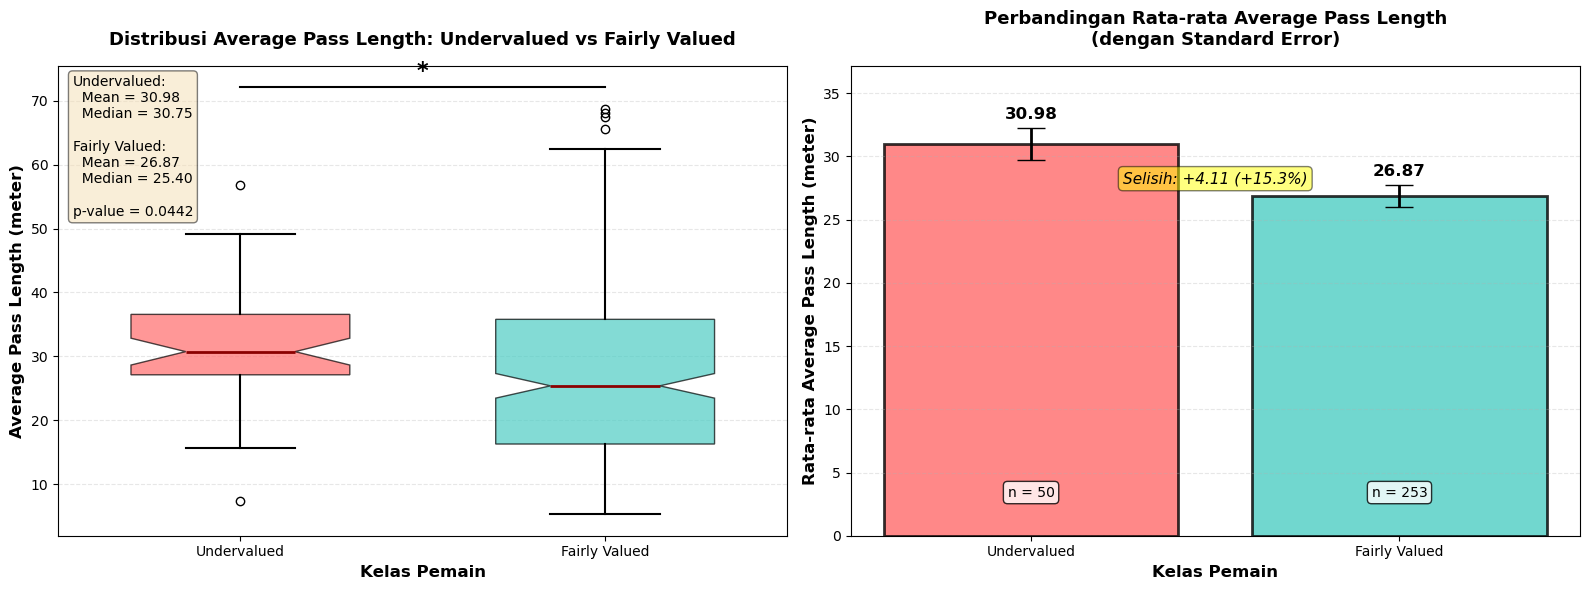


✓ Visualisasi disimpan: Perbandingan_Average_Pass_Length_Undervalued_vs_Fairly.png


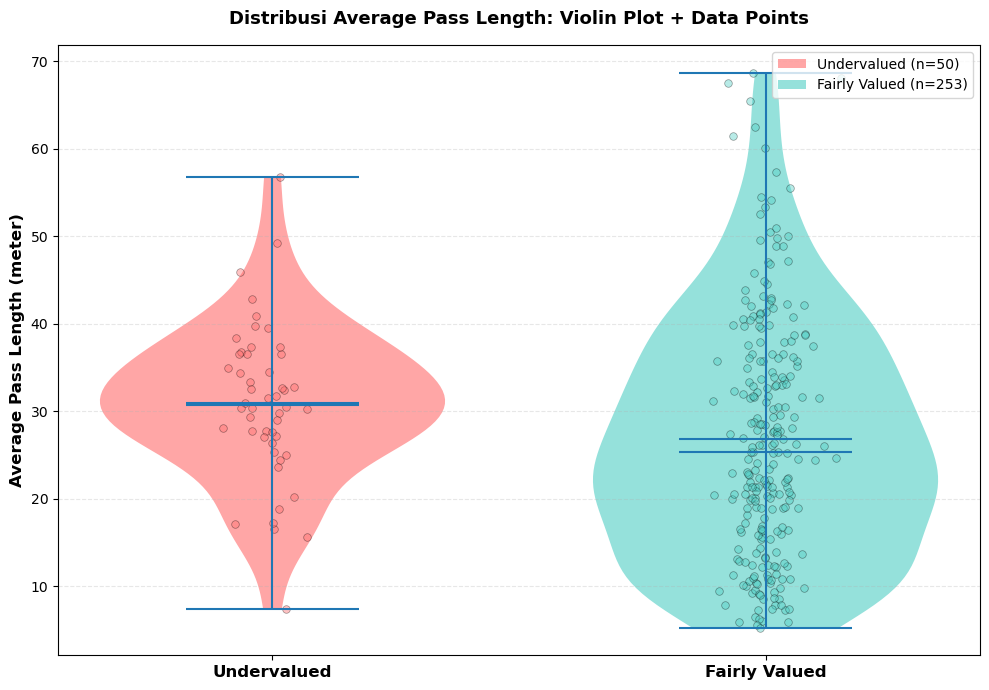

✓ Visualisasi tambahan disimpan: Violin_Plot_Average_Pass_Length.png

ANALISIS BREAKDOWN PER POSISI


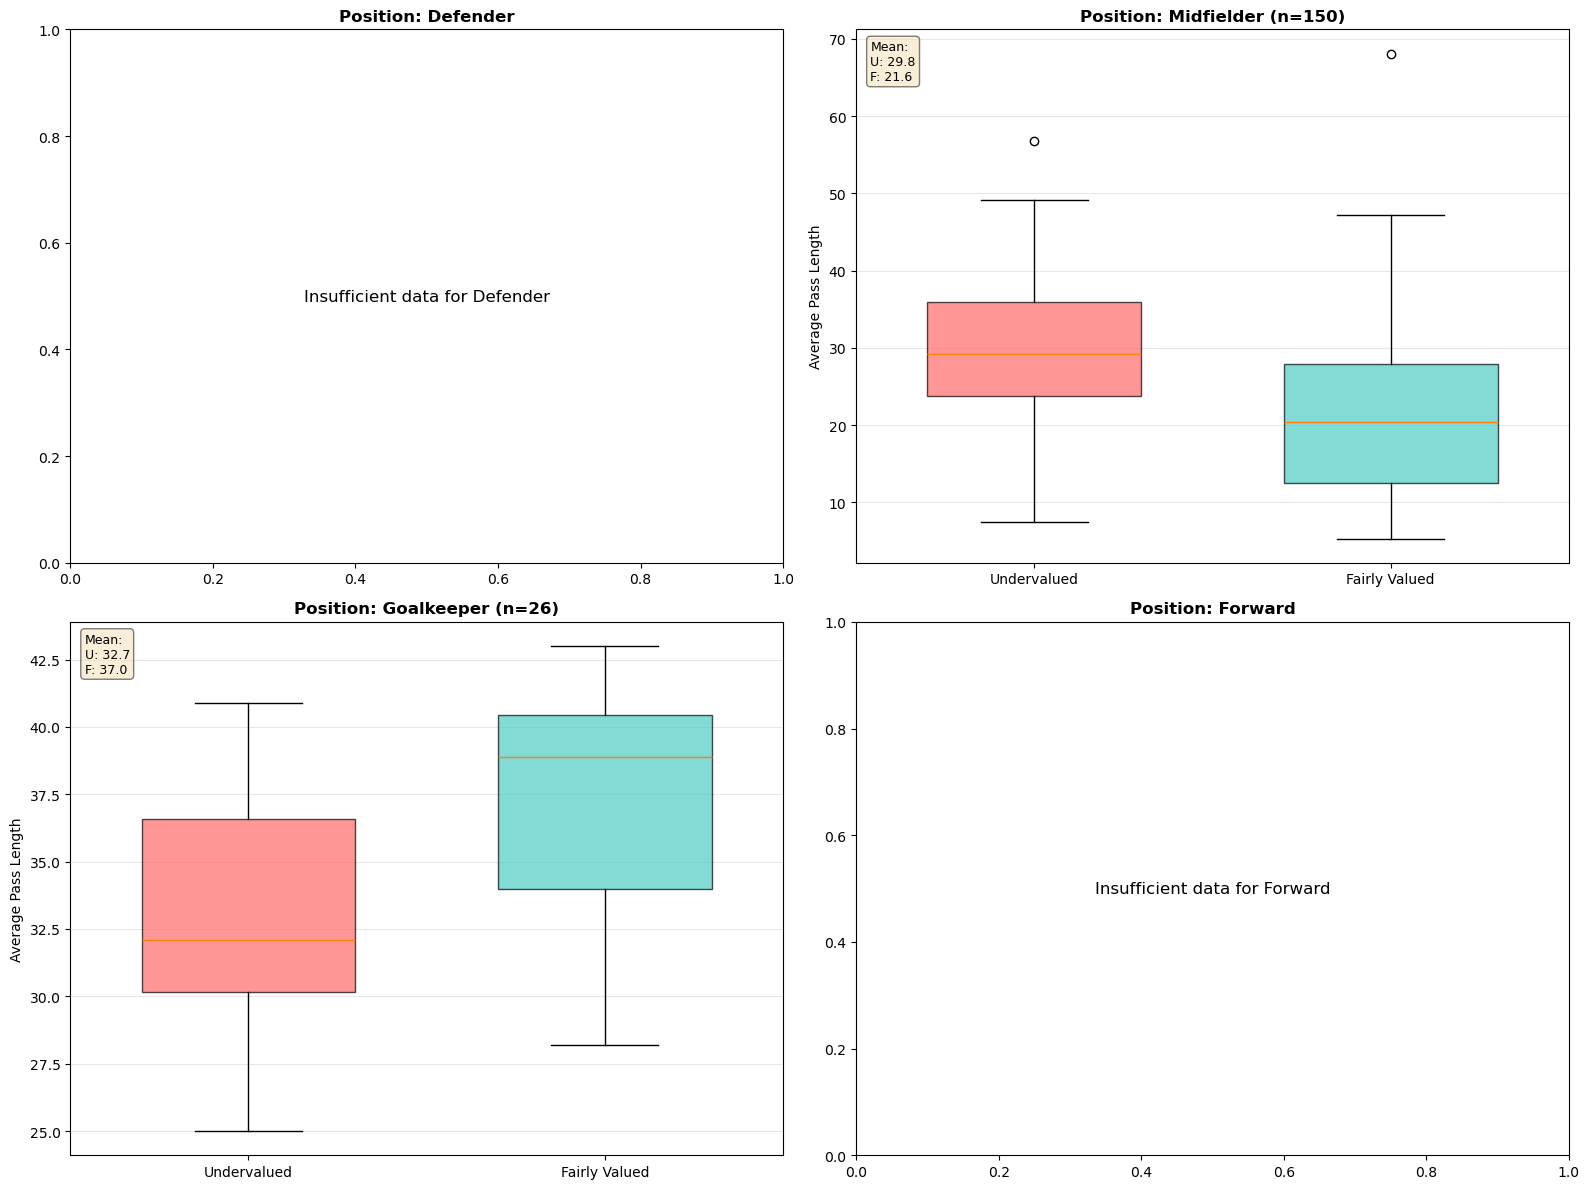

✓ Analisis per posisi disimpan: Average_Pass_Length_per_Position.png

INTERPRETASI & IMPLIKASI BISNIS

📊 TEMUAN UTAMA:

1. PERBEDAAN RATA-RATA:
   • Undervalued memiliki Average_pass_length rata-rata: 30.98 meter
   • Fairly Valued memiliki Average_pass_length rata-rata: 26.87 meter
   • Selisih: +4.11 meter (+15.3%)

2. SIGNIFIKANSI STATISTIK:
   • p-value = 0.0442
   • Kesimpulan: SIGNIFIKAN (p < 0.05) *

3. INTERPRETASI:

   ✓ Pemain UNDERVALUED cenderung memiliki rata-rata panjang umpan yang LEBIH TINGGI
     dibanding pemain Fairly Valued, dan perbedaan ini SIGNIFIKAN secara statistik.

   ✓ Ini menunjukkan bahwa kemampuan distribusi bola jarak jauh (long passing)
     adalah karakteristik penting yang membedakan pemain undervalued.

   ✓ Model Random Forest berhasil 'menangkap' pola ini sebagai salah satu fitur
     penting dalam klasifikasi (Average_pass_length sering masuk Top 3).

💡 IMPLIKASI UNTUK SCOUTING:
   • Pemain dengan Average_pass_length tinggi namun market value rend

In [ ]:
# ============================================================
# VISUALISASI PERBANDINGAN: Average_pass_length
# Undervalued vs Fairly Valued
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("ANALISIS KOMPARATIF: Average_pass_length")
print("Undervalued vs Fairly Valued")
print("="*80)

# ------------------------------------------------------------
# Load Data dan Feature Engineering
# ------------------------------------------------------------
df_original = pd.read_csv('../data/Data_Convert.csv' if os.path.exists('../data/Data_Convert.csv') else ('data/Data_Convert.csv' if os.path.exists('data/Data_Convert.csv') else 'Data_Convert.csv'))

weights = {
    'Forward': {'Goals': 0.35, 'Assist': 0.20, 'Shots_per_game': 0.15,
                'Key_passes': 0.15, 'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Midfielder': {'Assist': 0.25, 'Key_passes': 0.20, 'Goals': 0.15,
                   'Pass_success_accuracy': 0.15, 'Tackles': 0.10,
                   'Dribbles_per_game': 0.10, 'Man_of_the_Match': 0.05},
    'Defender': {'Tackles': 0.25, 'Clearances': 0.20, 'Interceptions': 0.20,
                 'Aerial_duels_won': 0.15, 'Pass_success_accuracy': 0.10,
                 'Blocks': 0.05, 'Man_of_the_Match': 0.05},
    'Goalkeeper': {'Pass_success_accuracy': 0.30, 'Long_balls': 0.25,
                   'Average_pass_length': 0.20, 'Aerial_duels_won': 0.15,
                   'Man_of_the_Match': 0.10}
}

def calculate_performance_score(row):
    pos = row['Position']
    score = 0.0
    if pos in weights:
        for feature, weight in weights[pos].items():
            score += row.get(feature, 0.0) * weight
    return score

df = df_original.copy()
df['Performance_Score'] = df.apply(calculate_performance_score, axis=1)
df['Perf_Score_Normalized'] = (df['Performance_Score'] - df['Performance_Score'].min()) / \
                               (df['Performance_Score'].max() - df['Performance_Score'].min())
df['MV_Normalized'] = (df['Market_Value'] - df['Market_Value'].min()) / \
                      (df['Market_Value'].max() - df['Market_Value'].min())
df['Perf_Quantile'] = pd.qcut(df['Perf_Score_Normalized'], 4, 
                               labels=['Q1','Q2','Q3','Q4'], duplicates='drop')
df['MV_Quantile'] = pd.qcut(df['MV_Normalized'], 4, 
                             labels=['Q1','Q2','Q3','Q4'], duplicates='drop')

def classify_alignment(row):
    perf_q, mv_q = row['Perf_Quantile'], row['MV_Quantile']
    if perf_q == 'Q4' and mv_q in ['Q1','Q2','Q3']:
        return 'Undervalued'
    elif mv_q == 'Q4' and perf_q in ['Q1','Q2','Q3']:
        return 'Overvalued'
    else:
        return 'Fairly Valued'

df['Alignment_Class'] = df.apply(classify_alignment, axis=1)

print(f"✓ Data berhasil diproses: {len(df)} pemain")
print(f"✓ Distribusi kelas:")
print(df['Alignment_Class'].value_counts())

# ------------------------------------------------------------
# Filter: Hanya Undervalued dan Fairly Valued
# ------------------------------------------------------------
df_comparison = df[df['Alignment_Class'].isin(['Undervalued', 'Fairly Valued'])].copy()

print(f"\n✓ Data untuk perbandingan: {len(df_comparison)} pemain")
print(f"  - Undervalued: {(df_comparison['Alignment_Class'] == 'Undervalued').sum()} pemain")
print(f"  - Fairly Valued: {(df_comparison['Alignment_Class'] == 'Fairly Valued').sum()} pemain")

# ------------------------------------------------------------
# Statistik Deskriptif
# ------------------------------------------------------------
print("\n" + "="*80)
print("STATISTIK DESKRIPTIF: Average_pass_length")
print("="*80)

stats_by_class = df_comparison.groupby('Alignment_Class')['Average_pass_length'].describe()
print("\n", stats_by_class)

# Hitung rata-rata per kelas
mean_undervalued = df_comparison[df_comparison['Alignment_Class'] == 'Undervalued']['Average_pass_length'].mean()
mean_fairly = df_comparison[df_comparison['Alignment_Class'] == 'Fairly Valued']['Average_pass_length'].mean()
median_undervalued = df_comparison[df_comparison['Alignment_Class'] == 'Undervalued']['Average_pass_length'].median()
median_fairly = df_comparison[df_comparison['Alignment_Class'] == 'Fairly Valued']['Average_pass_length'].median()

print(f"\n📊 RINGKASAN PERBANDINGAN:")
print(f"  Undervalued   - Mean: {mean_undervalued:.2f}, Median: {median_undervalued:.2f}")
print(f"  Fairly Valued - Mean: {mean_fairly:.2f}, Median: {median_fairly:.2f}")
print(f"  Selisih Mean  : {mean_undervalued - mean_fairly:.2f} ({((mean_undervalued/mean_fairly - 1)*100):+.1f}%)")

# ------------------------------------------------------------
# Uji Statistik (Independent t-test)
# ------------------------------------------------------------
print("\n" + "="*80)
print("UJI SIGNIFIKANSI STATISTIK (Independent t-test)")
print("="*80)

data_undervalued = df_comparison[df_comparison['Alignment_Class'] == 'Undervalued']['Average_pass_length'].dropna()
data_fairly = df_comparison[df_comparison['Alignment_Class'] == 'Fairly Valued']['Average_pass_length'].dropna()

# Uji normalitas (Shapiro-Wilk)
stat_norm_under, p_norm_under = stats.shapiro(data_undervalued)
stat_norm_fair, p_norm_fair = stats.shapiro(data_fairly)

print(f"\nUji Normalitas (Shapiro-Wilk):")
print(f"  Undervalued   - p-value: {p_norm_under:.4f} {'(Normal)' if p_norm_under > 0.05 else '(Tidak Normal)'}")
print(f"  Fairly Valued - p-value: {p_norm_fair:.4f} {'(Normal)' if p_norm_fair > 0.05 else '(Tidak Normal)'}")

# t-test (dua sampel independen)
t_stat, p_value = stats.ttest_ind(data_undervalued, data_fairly)

print(f"\nIndependent t-test:")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value    : {p_value:.4f}")

if p_value < 0.001:
    significance = "SANGAT SIGNIFIKAN (p < 0.001) ***"
elif p_value < 0.01:
    significance = "SIGNIFIKAN (p < 0.01) **"
elif p_value < 0.05:
    significance = "SIGNIFIKAN (p < 0.05) *"
else:
    significance = "TIDAK SIGNIFIKAN (p ≥ 0.05)"

print(f"  Kesimpulan : {significance}")

# Mann-Whitney U test (alternatif non-parametrik)
u_stat, p_value_mw = stats.mannwhitneyu(data_undervalued, data_fairly, alternative='two-sided')
print(f"\nMann-Whitney U test (Non-parametrik):")
print(f"  U-statistic: {u_stat:.4f}")
print(f"  p-value    : {p_value_mw:.4f}")

# ------------------------------------------------------------
# VISUALISASI 1: BOXPLOT
# ------------------------------------------------------------
print("\n" + "="*80)
print("MEMBUAT VISUALISASI...")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Boxplot
ax1 = axes[0]
boxplot_data = [data_undervalued, data_fairly]
bp = ax1.boxplot(boxplot_data, labels=['Undervalued', 'Fairly Valued'],
                  patch_artist=True, notch=True, widths=0.6)

# Warna boxplot
colors = ['#FF6B6B', '#4ECDC4']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Styling
for element in ['whiskers', 'fliers', 'means', 'medians', 'caps']:
    plt.setp(bp[element], color='black', linewidth=1.5)
plt.setp(bp['medians'], color='darkred', linewidth=2)

ax1.set_ylabel('Average Pass Length (meter)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Kelas Pemain', fontsize=12, fontweight='bold')
ax1.set_title('Distribusi Average Pass Length: Undervalued vs Fairly Valued',
              fontsize=13, fontweight='bold', pad=15)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Tambahkan informasi statistik
textstr = f'Undervalued:\n  Mean = {mean_undervalued:.2f}\n  Median = {median_undervalued:.2f}\n\n'
textstr += f'Fairly Valued:\n  Mean = {mean_fairly:.2f}\n  Median = {median_fairly:.2f}\n\n'
textstr += f'p-value = {p_value:.4f}'
ax1.text(0.02, 0.98, textstr, transform=ax1.transAxes, fontsize=10,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Tambahkan anotasi signifikansi
if p_value < 0.05:
    y_max = max(data_undervalued.max(), data_fairly.max())
    ax1.plot([1, 2], [y_max * 1.05, y_max * 1.05], 'k-', linewidth=1.5)
    star = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*'
    ax1.text(1.5, y_max * 1.07, star, ha='center', fontsize=16, fontweight='bold')

# ------------------------------------------------------------
# VISUALISASI 2: BAR CHART (Mean dengan Error Bar)
# ------------------------------------------------------------
ax2 = axes[1]

classes = ['Undervalued', 'Fairly Valued']
means = [mean_undervalued, mean_fairly]
stds = [data_undervalued.std(), data_fairly.std()]
sems = [data_undervalued.sem(), data_fairly.sem()]  # Standard Error of Mean

x_pos = np.arange(len(classes))
bars = ax2.bar(x_pos, means, yerr=sems, capsize=10, 
               color=colors, alpha=0.8, edgecolor='black', linewidth=2,
               error_kw={'linewidth': 2, 'ecolor': 'black'})

# Tambahkan nilai di atas bar
for i, (bar, mean_val) in enumerate(zip(bars, means)):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + sems[i] + 0.5,
            f'{mean_val:.2f}', ha='center', va='bottom', 
            fontsize=12, fontweight='bold')

ax2.set_ylabel('Rata-rata Average Pass Length (meter)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Kelas Pemain', fontsize=12, fontweight='bold')
ax2.set_title('Perbandingan Rata-rata Average Pass Length\n(dengan Standard Error)',
              fontsize=13, fontweight='bold', pad=15)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(classes)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.set_ylim([0, max(means) * 1.2])

# Tambahkan informasi sample size
for i, kelas in enumerate(classes):
    n = len(data_undervalued) if kelas == 'Undervalued' else len(data_fairly)
    ax2.text(i, max(means) * 0.1, f'n = {n}', ha='center', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Tambahkan anotasi selisih
diff_pct = ((mean_undervalued / mean_fairly) - 1) * 100
ax2.annotate(f'Selisih: {mean_undervalued - mean_fairly:+.2f} ({diff_pct:+.1f}%)',
            xy=(0.5, max(means) * 0.9), xycoords='data',
            ha='center', fontsize=11, style='italic',
            bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

plt.tight_layout()
plt.savefig('Perbandingan_Average_Pass_Length_Undervalued_vs_Fairly.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Visualisasi disimpan: Perbandingan_Average_Pass_Length_Undervalued_vs_Fairly.png")

# ------------------------------------------------------------
# VISUALISASI TAMBAHAN: Violin Plot + Strip Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7))

# Violin plot untuk melihat distribusi lengkap
parts = ax.violinplot([data_undervalued, data_fairly], 
                       positions=[1, 2], 
                       showmeans=True, 
                       showmedians=True,
                       widths=0.7)

# Warna violin
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.6)

# Strip plot overlay untuk melihat data points
for i, (kelas, data, color) in enumerate(zip(classes, [data_undervalued, data_fairly], colors)):
    # Jitter untuk visibility
    y = data
    x = np.random.normal(i+1, 0.04, size=len(data))
    ax.scatter(x, y, alpha=0.4, s=30, color=color, edgecolor='black', linewidth=0.5)

ax.set_xticks([1, 2])
ax.set_xticklabels(classes, fontsize=12, fontweight='bold')
ax.set_ylabel('Average Pass Length (meter)', fontsize=12, fontweight='bold')
ax.set_title('Distribusi Average Pass Length: Violin Plot + Data Points',
             fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Legenda
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.6, label=f'Undervalued (n={len(data_undervalued)})'),
    Patch(facecolor=colors[1], alpha=0.6, label=f'Fairly Valued (n={len(data_fairly)})')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig('Violin_Plot_Average_Pass_Length.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualisasi tambahan disimpan: Violin_Plot_Average_Pass_Length.png")

# ------------------------------------------------------------
# ANALISIS PER POSISI
# ------------------------------------------------------------
print("\n" + "="*80)
print("ANALISIS BREAKDOWN PER POSISI")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

positions = df_comparison['Position'].unique()

for idx, pos in enumerate(positions):
    if idx >= 4:
        break
    
    df_pos = df_comparison[df_comparison['Position'] == pos]
    
    # Skip jika tidak ada data untuk kedua kelas
    if len(df_pos['Alignment_Class'].unique()) < 2:
        axes[idx].text(0.5, 0.5, f'Insufficient data for {pos}', 
                      ha='center', va='center', fontsize=12)
        axes[idx].set_title(f'Position: {pos}', fontweight='bold')
        continue
    
    # Boxplot per posisi
    data_pos = [
        df_pos[df_pos['Alignment_Class'] == 'Undervalued']['Average_pass_length'].dropna(),
        df_pos[df_pos['Alignment_Class'] == 'Fairly Valued']['Average_pass_length'].dropna()
    ]
    
    bp = axes[idx].boxplot(data_pos, labels=['Undervalued', 'Fairly Valued'],
                           patch_artist=True, notch=False, widths=0.6)
    
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[idx].set_title(f'Position: {pos} (n={len(df_pos)})', 
                       fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Average Pass Length', fontsize=10)
    axes[idx].grid(axis='y', alpha=0.3)
    
    # Tambahkan mean
    if len(data_pos[0]) > 0 and len(data_pos[1]) > 0:
        mean_u = data_pos[0].mean()
        mean_f = data_pos[1].mean()
        axes[idx].text(0.02, 0.98, f'Mean:\nU: {mean_u:.1f}\nF: {mean_f:.1f}',
                      transform=axes[idx].transAxes, fontsize=9,
                      verticalalignment='top',
                      bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('Average_Pass_Length_per_Position.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Analisis per posisi disimpan: Average_Pass_Length_per_Position.png")

# ------------------------------------------------------------
# INTERPRETASI BISNIS
# ------------------------------------------------------------
print("\n" + "="*80)
print("INTERPRETASI & IMPLIKASI BISNIS")
print("="*80)

interpretasi = f"""
📊 TEMUAN UTAMA:

1. PERBEDAAN RATA-RATA:
   • Undervalued memiliki Average_pass_length rata-rata: {mean_undervalued:.2f} meter
   • Fairly Valued memiliki Average_pass_length rata-rata: {mean_fairly:.2f} meter
   • Selisih: {mean_undervalued - mean_fairly:+.2f} meter ({diff_pct:+.1f}%)

2. SIGNIFIKANSI STATISTIK:
   • p-value = {p_value:.4f}
   • Kesimpulan: {significance}
   
3. INTERPRETASI:
"""

if mean_undervalued > mean_fairly and p_value < 0.05:
    interpretasi += f"""
   ✓ Pemain UNDERVALUED cenderung memiliki rata-rata panjang umpan yang LEBIH TINGGI
     dibanding pemain Fairly Valued, dan perbedaan ini SIGNIFIKAN secara statistik.
   
   ✓ Ini menunjukkan bahwa kemampuan distribusi bola jarak jauh (long passing)
     adalah karakteristik penting yang membedakan pemain undervalued.
   
   ✓ Model Random Forest berhasil 'menangkap' pola ini sebagai salah satu fitur
     penting dalam klasifikasi (Average_pass_length sering masuk Top 3).

💡 IMPLIKASI UNTUK SCOUTING:
   • Pemain dengan Average_pass_length tinggi namun market value rendah adalah
     kandidat KUAT untuk kategori undervalued
   • Klub harus fokus pada pemain yang mampu 'membuka permainan' dengan passing
     jarak jauh, karena skill ini kurang dihargai di pasar
   • Ini sejalan dengan filosofi Eredivisie yang menekankan technical ability
     dan vision dalam permainan
"""
elif mean_undervalued < mean_fairly and p_value < 0.05:
    interpretasi += f"""
   ✓ Pemain UNDERVALUED cenderung memiliki rata-rata panjang umpan yang LEBIH RENDAH
     dibanding pemain Fairly Valued, dan perbedaan ini SIGNIFIKAN.
   
   ✓ Ini bisa mengindikasikan bahwa pemain undervalued lebih fokus pada short passing
     dan build-up play yang lebih technical.

💡 IMPLIKASI UNTUK SCOUTING:
   • Pasar mungkin lebih menghargai pemain dengan long passing (spektakuler)
   • Pemain dengan short passing excellent tapi kurang 'flashy' bisa undervalued
"""
else:
    interpretasi += f"""
   ⚠️ Perbedaan rata-rata Average_pass_length TIDAK SIGNIFIKAN secara statistik
   
   ✓ Ini berarti Average_pass_length saja tidak cukup untuk membedakan pemain
     undervalued dari fairly valued
   
   ✓ Model menggunakan kombinasi banyak fitur, bukan hanya satu fitur tunggal

💡 IMPLIKASI UNTUK SCOUTING:
   • Evaluasi harus holistik, tidak fokus pada satu metrik saja
   • Kombinasi fitur lebih penting daripada fitur individual
"""

print(interpretasi)

# Simpan ringkasan ke file
summary_data = {
    'Kelas': ['Undervalued', 'Fairly Valued'],
    'N': [len(data_undervalued), len(data_fairly)],
    'Mean': [mean_undervalued, mean_fairly],
    'Median': [median_undervalued, median_fairly],
    'Std': [data_undervalued.std(), data_fairly.std()],
    'Min': [data_undervalued.min(), data_fairly.min()],
    'Max': [data_undervalued.max(), data_fairly.max()]
}

df_summary = pd.DataFrame(summary_data)
df_summary.to_csv('Summary_Average_Pass_Length_Comparison.csv', index=False)

print("\n✓ Ringkasan statistik disimpan: Summary_Average_Pass_Length_Comparison.csv")

print("\n" + "="*80)
print("ANALISIS SELESAI")
print("="*80)
print("\n✓ File yang dihasilkan:")
print("  1. Perbandingan_Average_Pass_Length_Undervalued_vs_Fairly.png")
print("  2. Violin_Plot_Average_Pass_Length.png")
print("  3. Average_Pass_Length_per_Position.png")
print("  4. Summary_Average_Pass_Length_Comparison.csv")
